# Monte Carlo 
## ejemplos


In [349]:
import numpy as np
import matplotlib.pyplot as plt

#crea un generador de números pseudoaleatorios con una semilla fija, de modo que los resultados sean reproducibles.
rng = np.random.default_rng(42)
import matplotlib

In [350]:
font = {'size'   : 13}
matplotlib.rc('font', **font)
matplotlib.rc('xtick', labelsize=10) 
matplotlib.rc('ytick', labelsize=10) 
matplotlib.rcParams['figure.dpi'] = 300

## Estimar $\pi$

Generaremos puntos aleatorios dentro de un cuadrado y contaremos cuántos caen dentro del círculo unitario.

La idea aquí es observar cómo una cantidad conocida puede estimarse a partir de muchas realizaciones aleatorias.


In [3]:
N = 10 #cambie este valor!

#Generamos N puntos aleatorios uniformemente distribuidos dentro del cuadrado [-1,1]x[-1,1]
x = rng.uniform(-1, 1, N)
y = rng.uniform(-1, 1, N)

dentro = x**2 + y**2 <= 1

pi_estimado = 4 * dentro.mean()

print(f"Estimación de pi: {pi_estimado:.5f}")
print(f"Valor de referencia: {np.pi:.5f}")


Estimación de pi: 3.20000
Valor de referencia: 3.14159


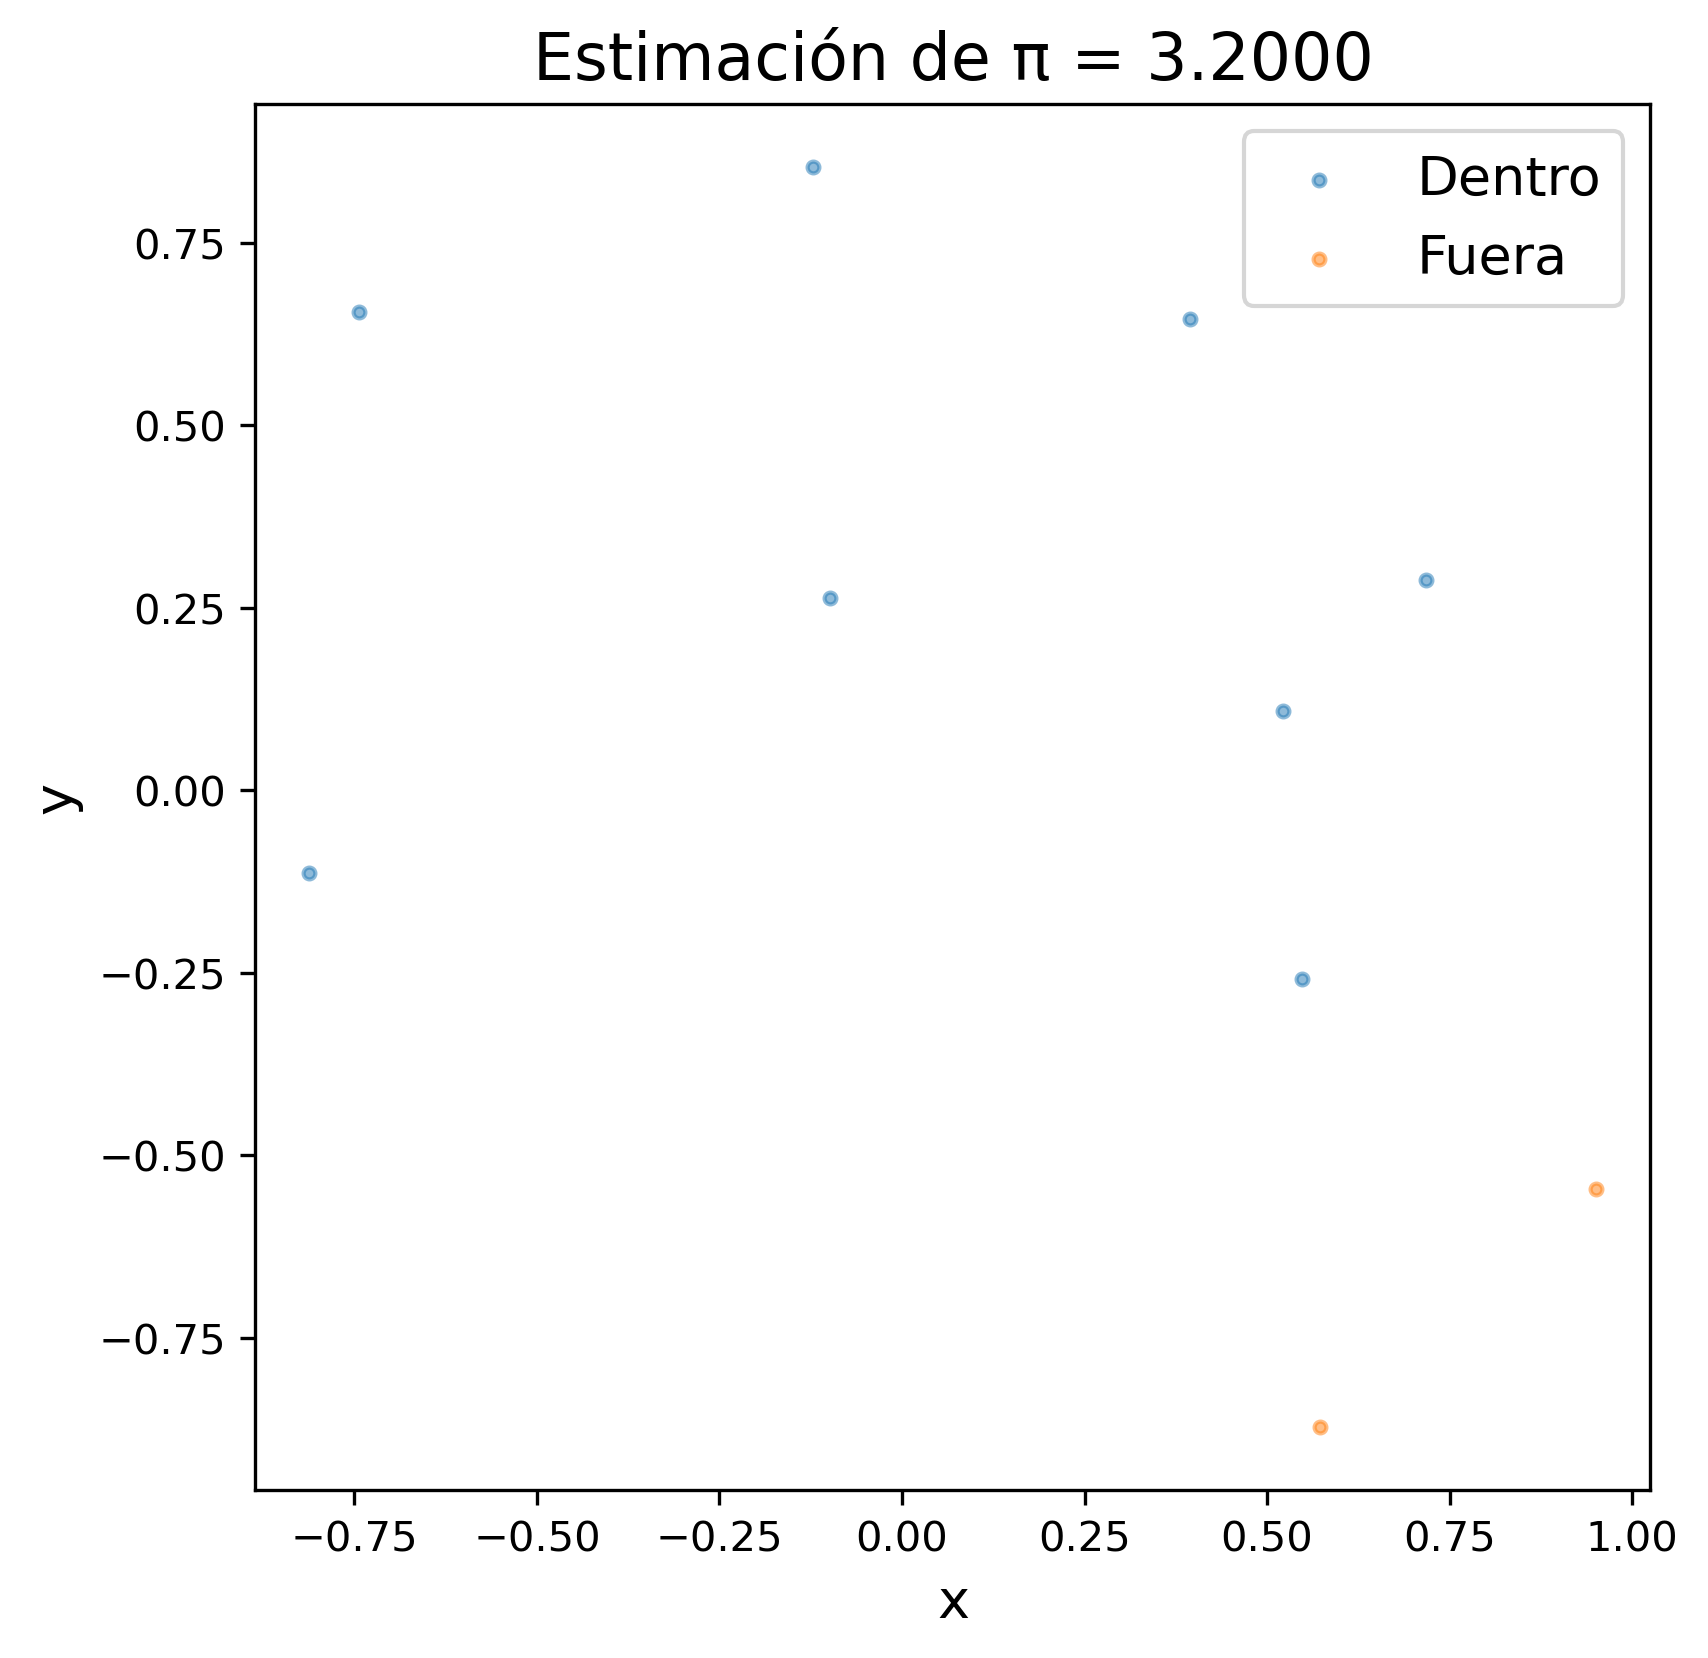

In [4]:
plt.figure(figsize=(6, 6))

plt.scatter(x[dentro], y[dentro], s=8, alpha=0.5, label="Dentro")
plt.scatter(x[~dentro], y[~dentro], s=8, alpha=0.5, label="Fuera")

plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.legend()

plt.title(f"Estimación de π = {pi_estimado:.4f}")

plt.show()


## La variable auxiliar uniforme

Antes de aplicar la transformación inversa, generamos la variable auxiliar
$$
U \sim U(0,1)
$$

Esta variable será el punto de partida del muestreo. Primero verificaremos cómo se comporta una muestra uniforme y luego transformaremos esos valores mediante $F^{-1}$ para obtener la distribución deseada.


In [5]:
#Generamos N realizaciones de una variable uniforme entre 0 y 1 y visualizamos las primeras 10 muestras.
N = 10000 #cambie este numero!

u = rng.random(N)

print(u[:10])


[0.75808774 0.35452597 0.97069802 0.89312112 0.7783835  0.19463871
 0.466721   0.04380377 0.15428949 0.68304895]


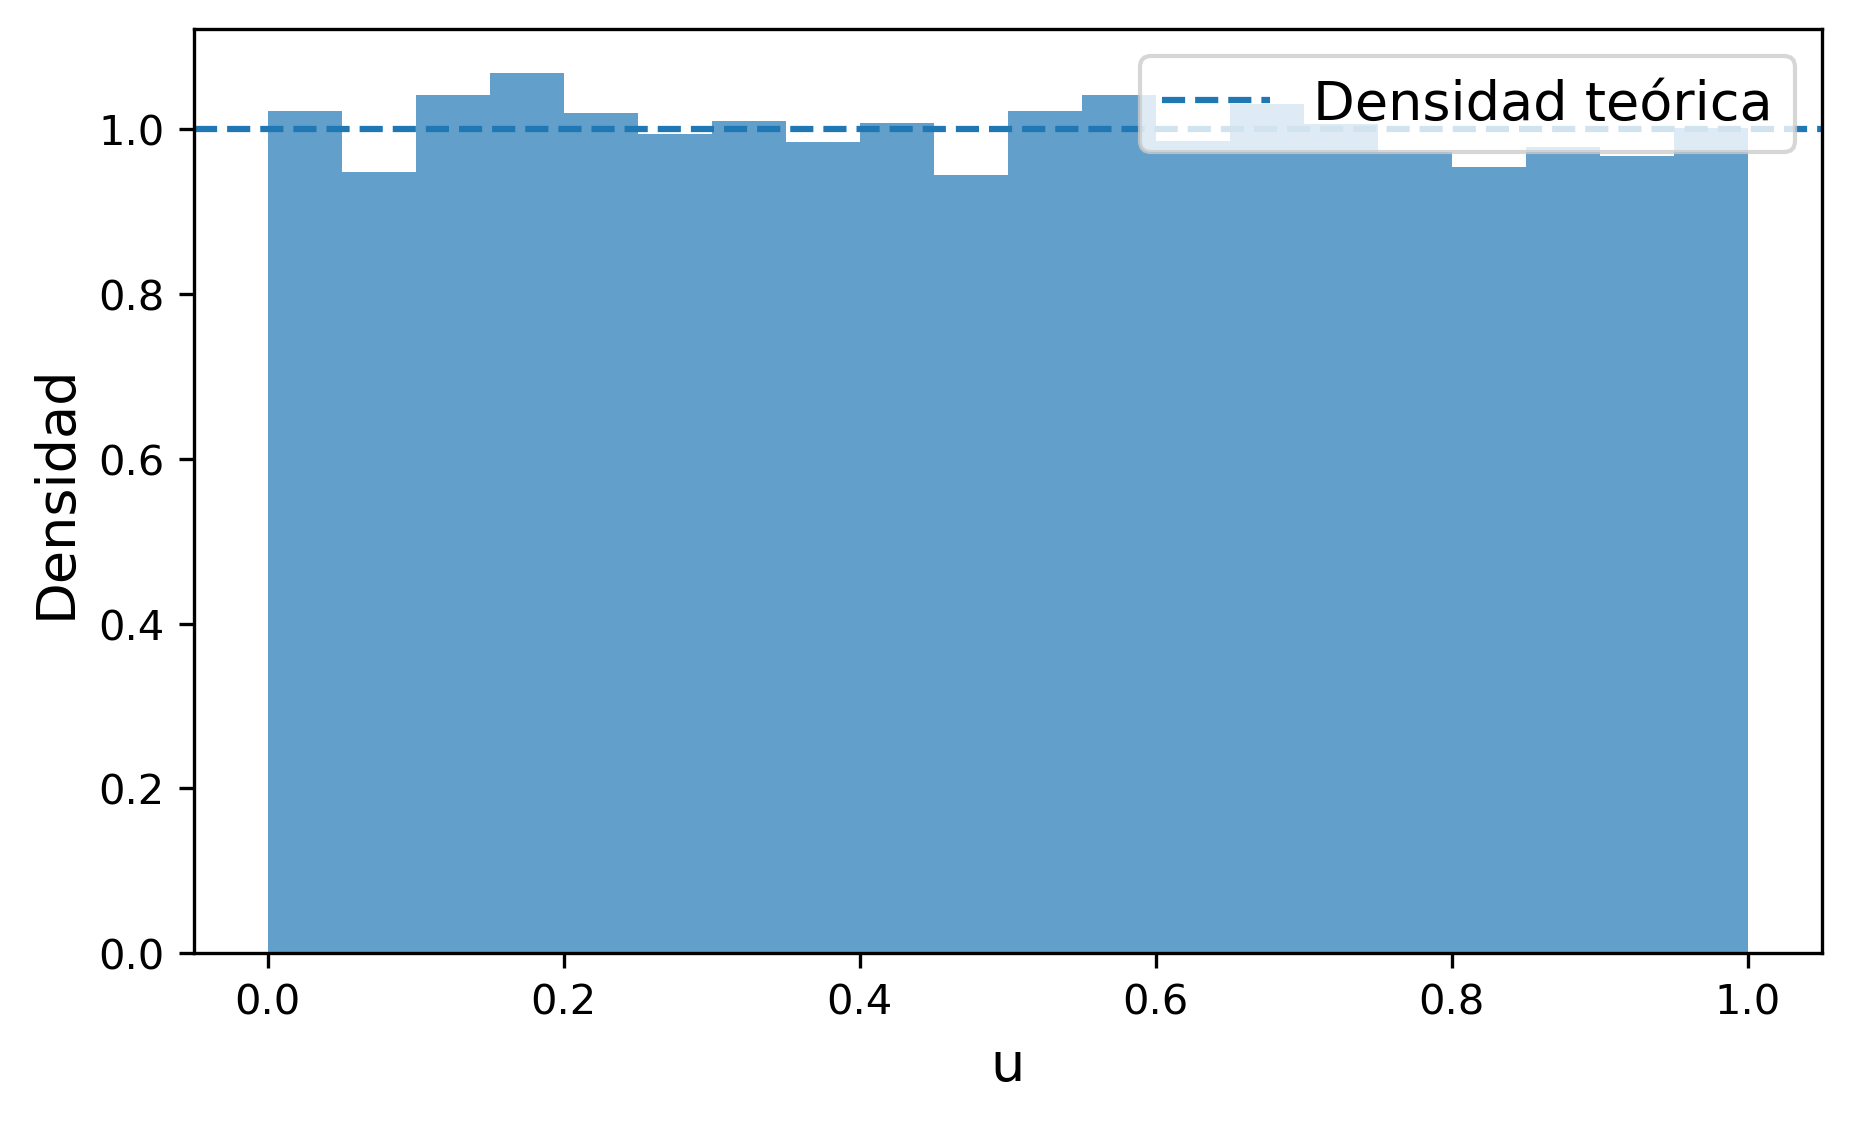

In [6]:
plt.figure(figsize=(7, 4))

plt.hist(u, bins=20, density=True, alpha=0.7)
plt.axhline(1, linestyle="--", label="Densidad teórica")

plt.xlabel("u")
plt.ylabel("Densidad")
plt.legend()
plt.show()


### Preguntas:

- ¿El histograma es perfectamente plano?
  No, no es perfectamente plano. Hay pequeñas "desviaciones" e irregularidades cuando se tiende a 1, pero cada vez son menos al aumentar las realizaciones.
- ¿Por qué aparecen pequeñas fluctuaciones entre bins? Porque muchas cantidades físicas no siguen distribuciones uniforme de manera que se intenta que toda la distribución siga una distribución uniforme. Muchos sistemas físicos presentan distribuciones altamente asimétricos.
- ¿Qué esperamos que ocurra si aumentamos mucho $N$? Cada vez van a existir menos irregularidades.


## Muestreo de una ley de potencias

En el ejemplo de clase obtuvimos, para

$$
p(x)=\frac{10}{9}x^{-2}
$$

con

$$
1\leq x\leq 10
$$

la transformación

$$
x=\frac{1}{1-0.9u}
$$

Ahora aplicaremos esa transformación a una muestra uniforme.


In [7]:
#genera N valores u entre 0 y 1 y transforma cada uno usando x=F^-1(u)
N = 1000000 #cambie este valor!

u = rng.random(N)
x = 1 / (1 - 0.9 * u) #los valores x deberian seguir aproximadamente p(x) ~ x^-2

print(x[:10]) 
print(f"Mínimo de la muestra: {x.min():.3f}")
print(f"Máximo de la muestra: {x.max():.3f}")


[1.18050606 1.34458346 1.39012422 9.68912365 1.23933408 1.13158874
 5.99241218 1.17060054 4.79275935 2.41202713]
Mínimo de la muestra: 1.000
Máximo de la muestra: 10.000


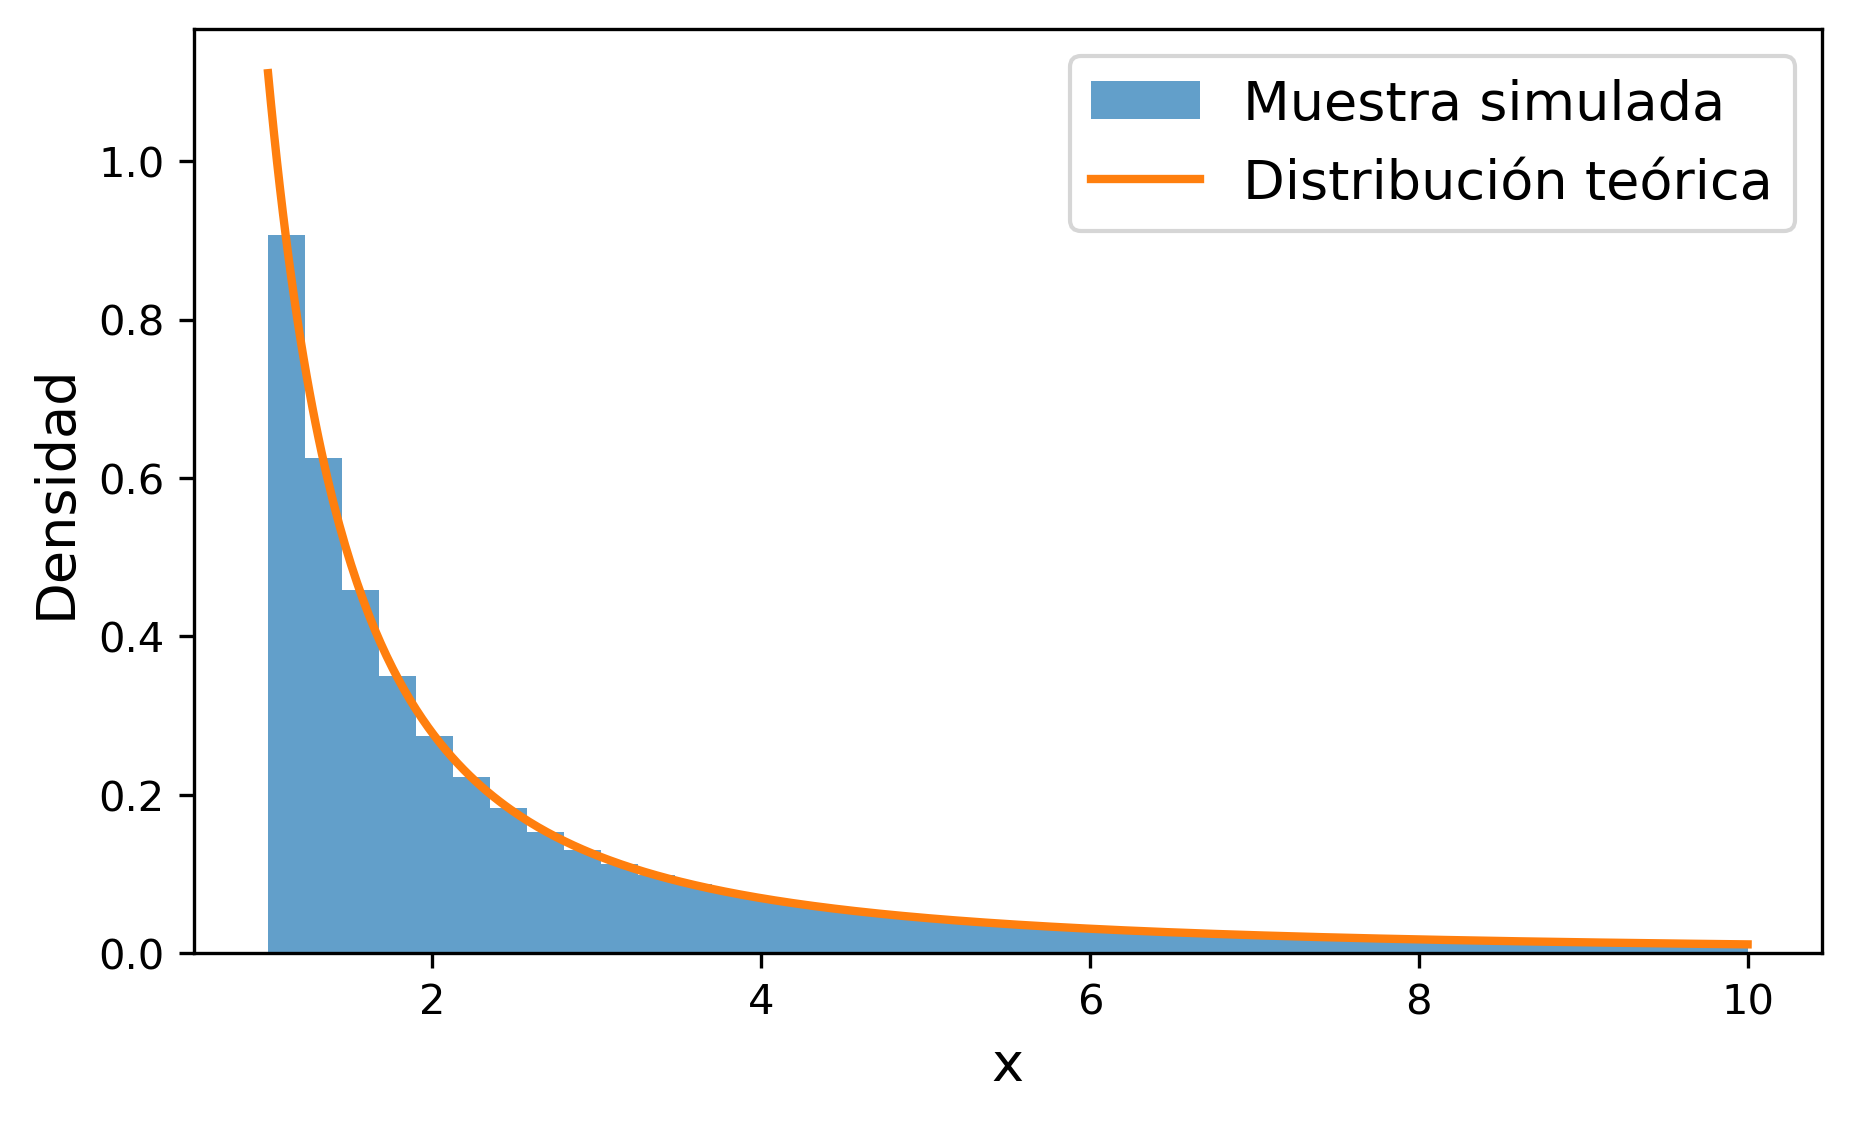

In [8]:
#comprobación visual
x_teorico = np.linspace(1, 10, 500)
p_teorica = (10 / 9) * x_teorico**(-2)

plt.figure(figsize=(7, 4))

plt.hist(x, bins=40, density=True, alpha=0.7, label="Muestra simulada")
plt.plot(x_teorico, p_teorica, linewidth=2, label="Distribución teórica")

plt.xlabel("x")
plt.ylabel("Densidad")
plt.legend()
plt.show()


### Preguntas rápidas

- La muestra original `u` era uniforme ¿por qué el histograma de `x` ya no es uniforme? Porque se ha realizado la inversa de manera que se realiza el sistema de probabilidad contenido en F-1(U) siendo esto acumulado a lo largo de los x.
- ¿En qué región aparecen más realizaciones? Entre x=1 y x=2 aparecen más realizaciones.
- ¿El histograma reproduce razonablemente la forma de la distribución teórica? Quizás porque antes llegando a 1 se incluye como el máximo para la misma muestra uniforme, y en esta parte se representan los valores acumulados.
- ¿Sería suficiente comprobar que el código corre sin errores para afirmar que el muestreo es correcto? No, no es suficiente. Para afirmar que el muestreo es correcto se debe validar si corresponde a la teoría, además de si es físico para el fenómeno que se esté estudiando.

## Validación y número de realizaciones

Repetiremos el mismo muestreo usando distintos valores de $N$

Nos interesa distinguir entre:

- la distribución que queremos simular
- qué tan bien una muestra finita representa esa distribución


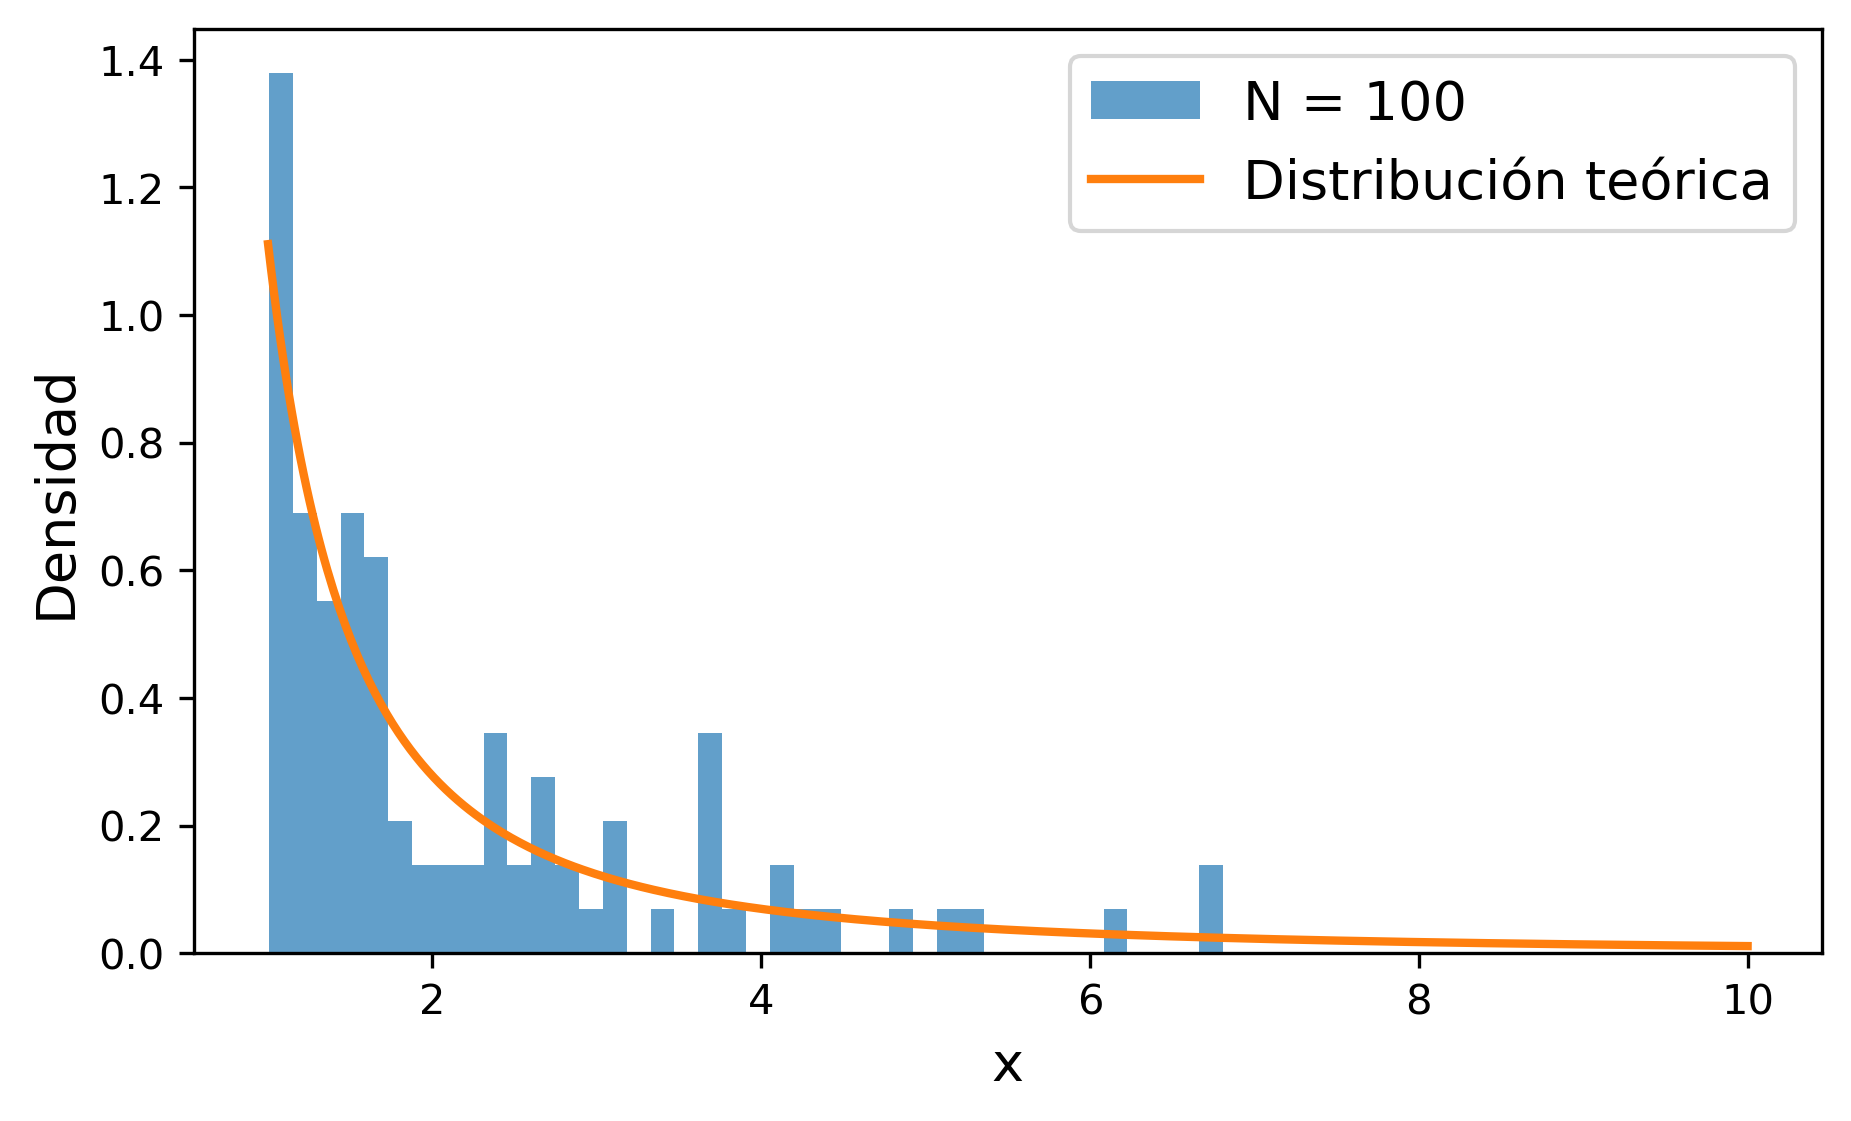

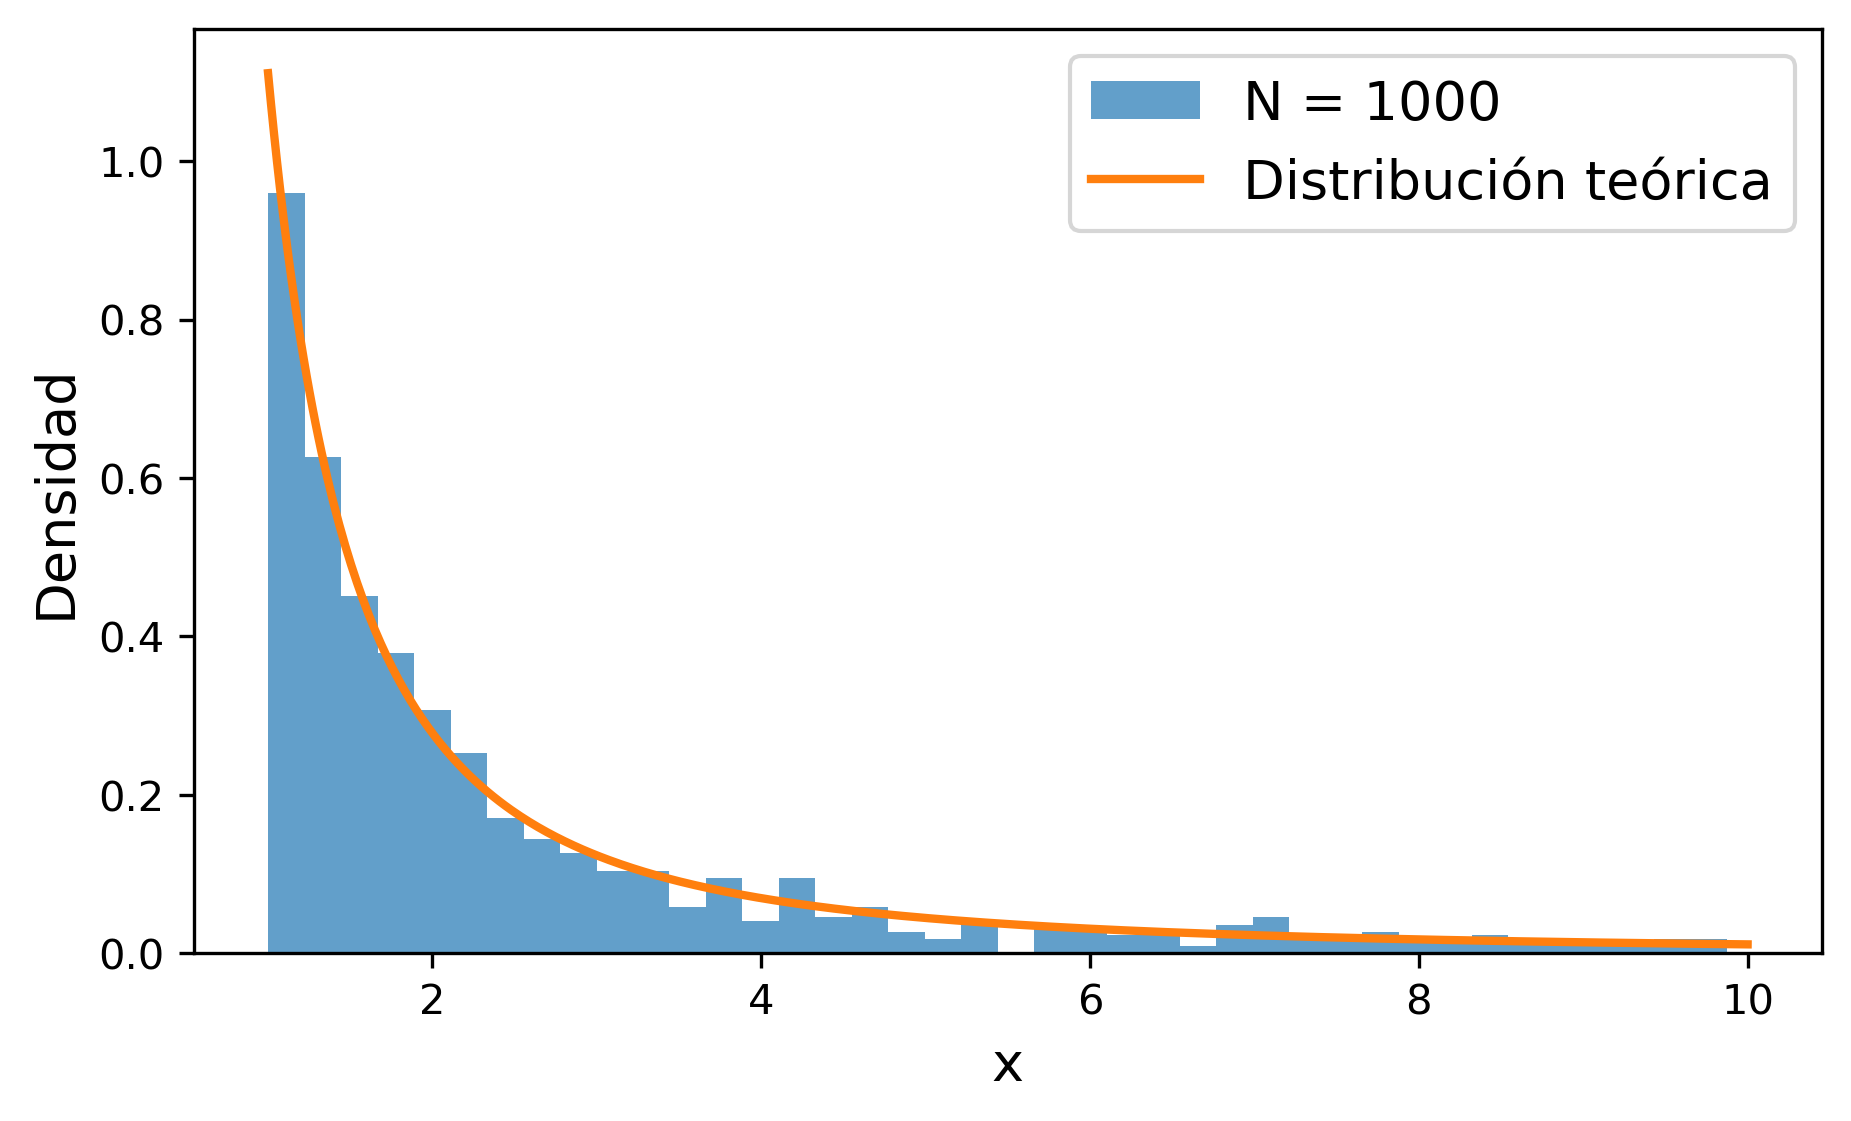

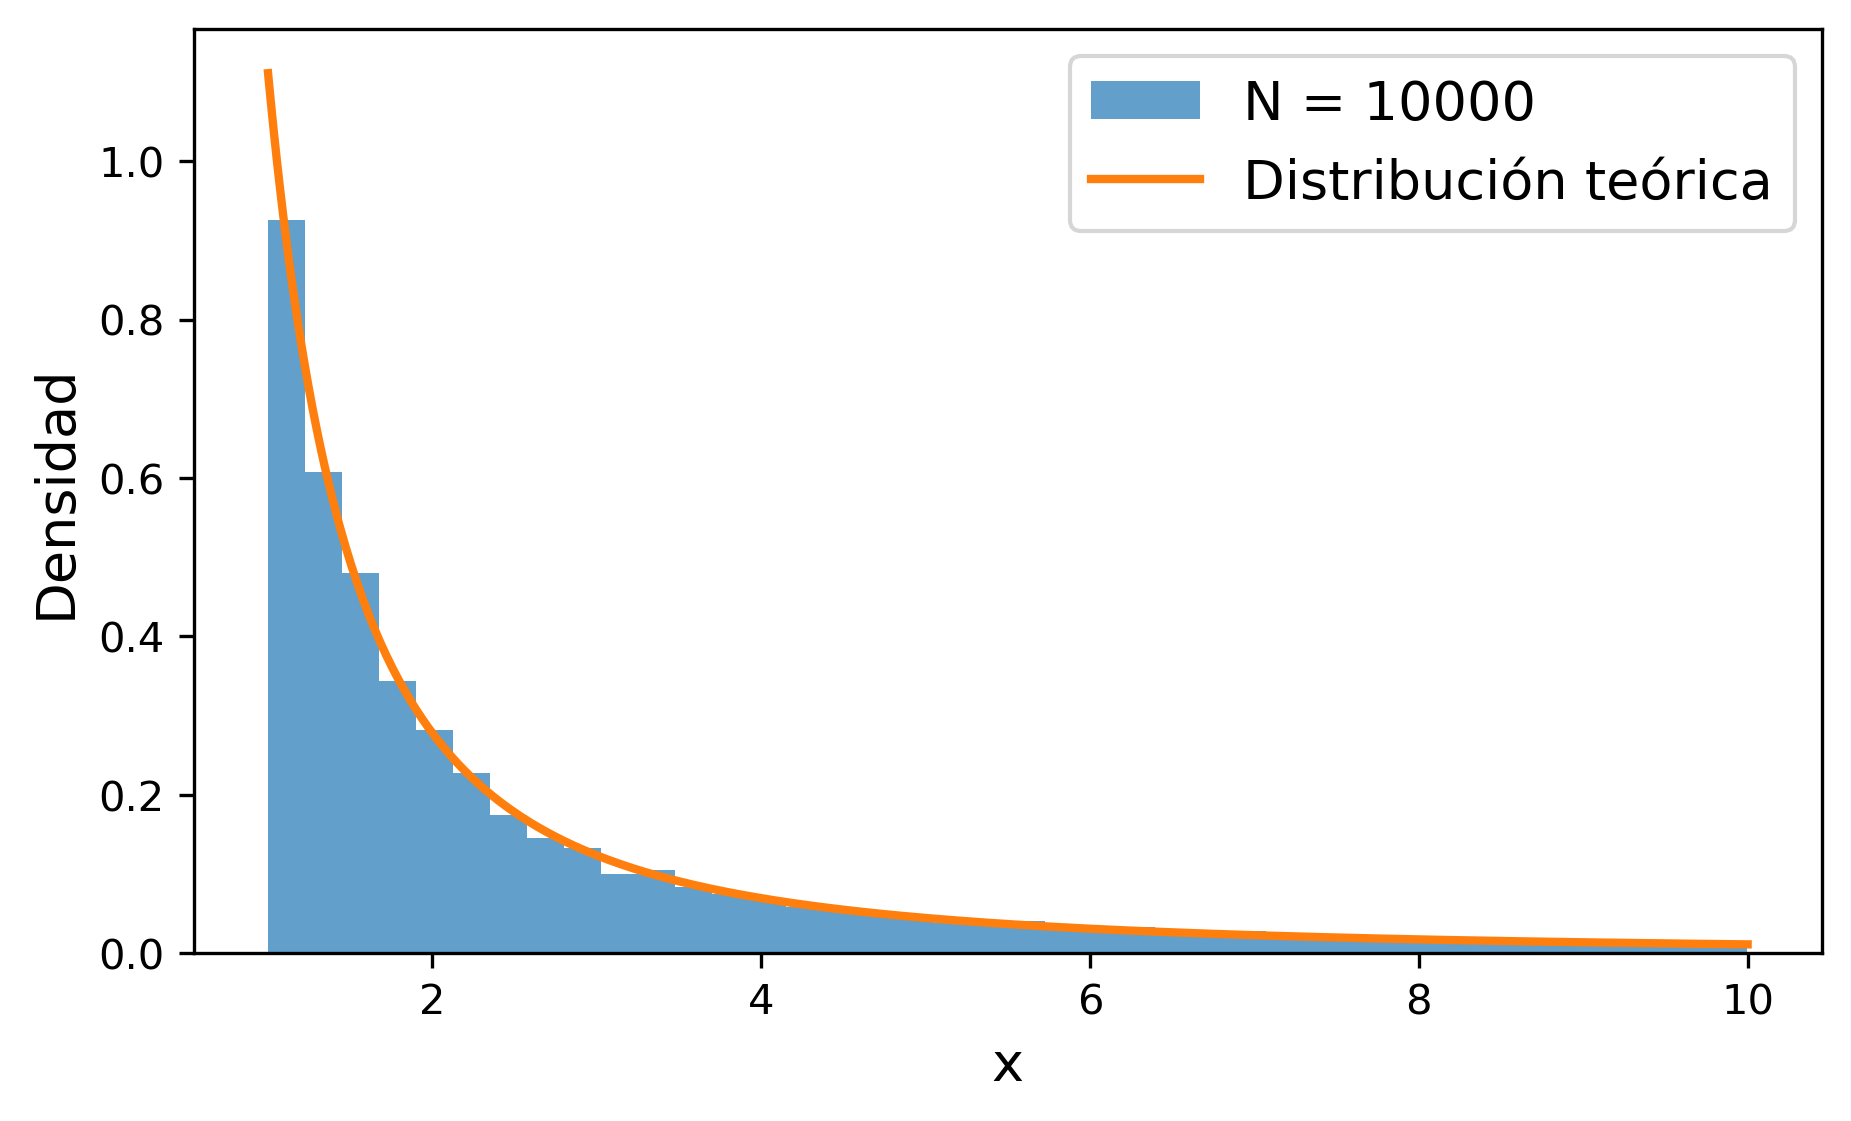

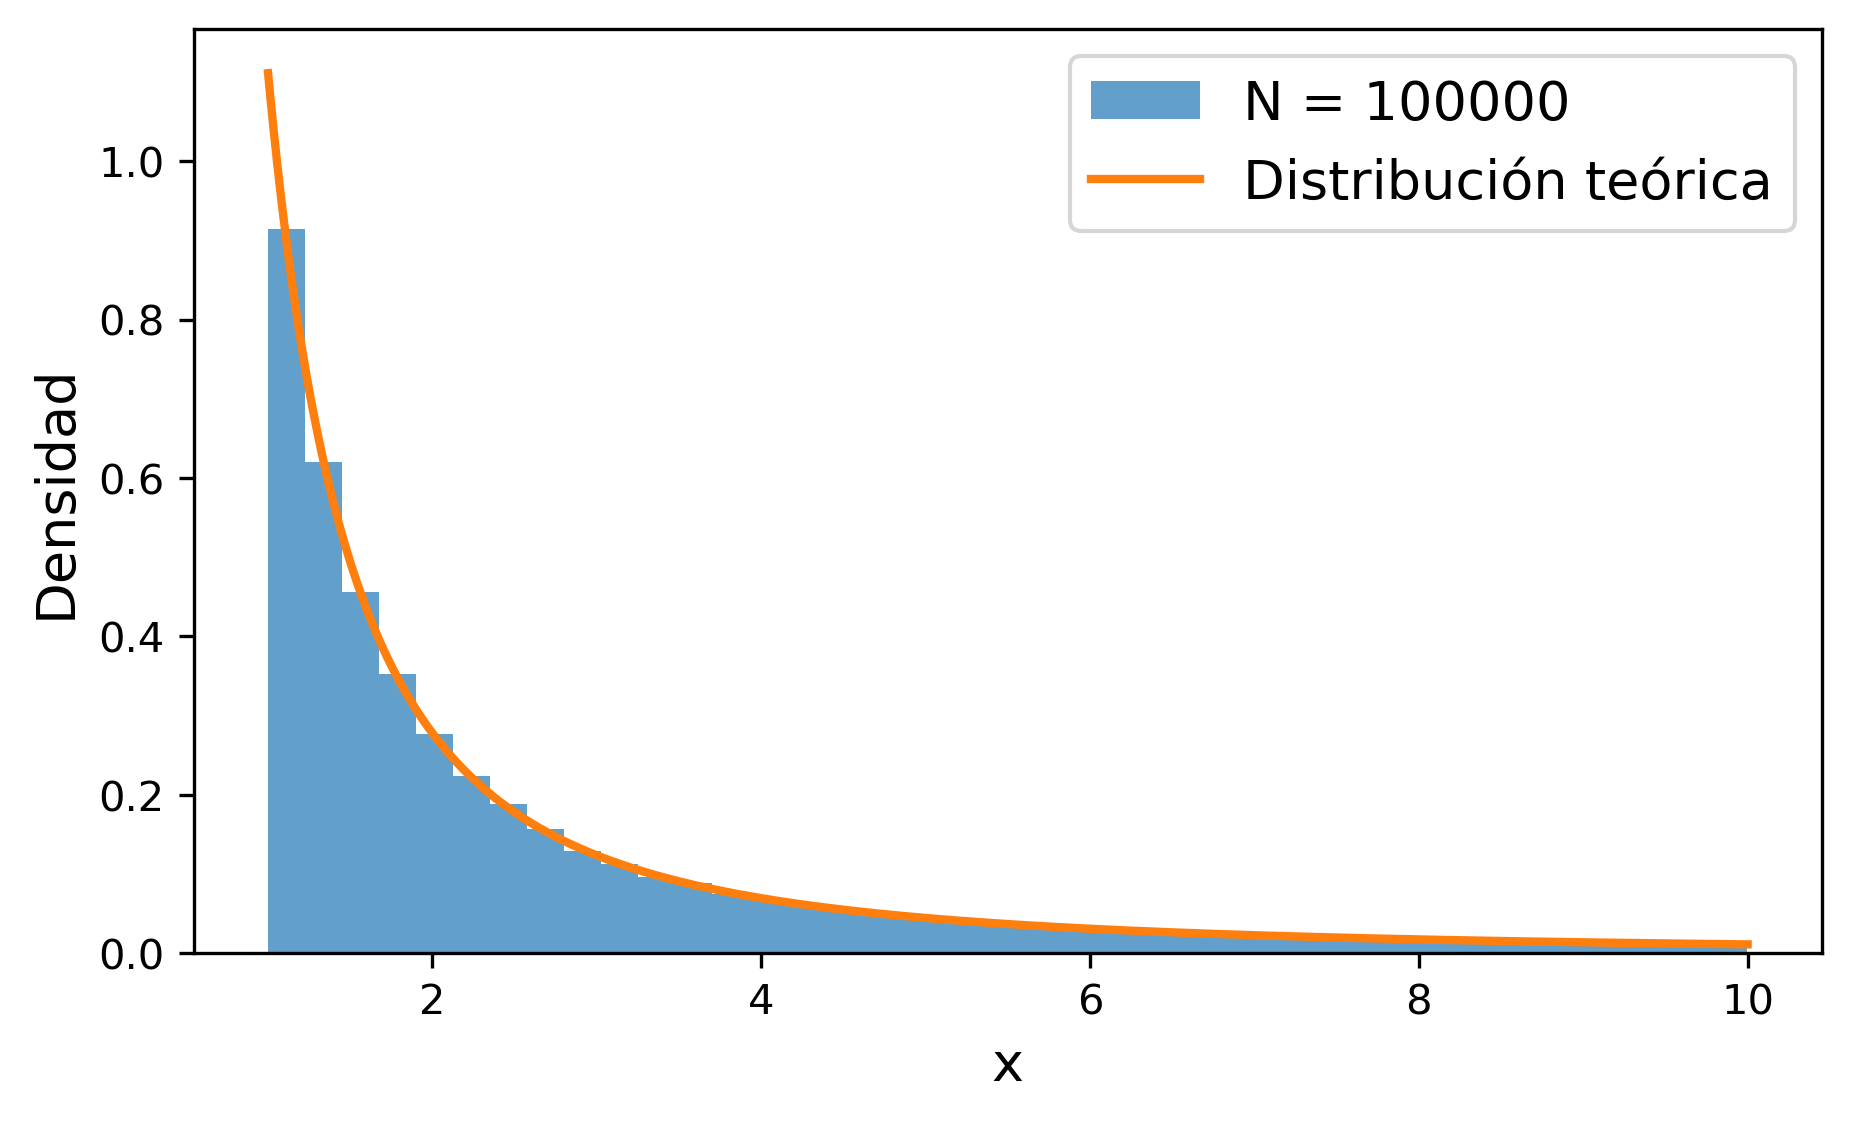

In [9]:
valores_N = [100, 1000, 10000, 100000]

for N in valores_N:
    u = rng.random(N) #valores aleatorios para los distintas realizaciones
    x = 1 / (1 - 0.9 * u)

    plt.figure(figsize=(7, 4))
    plt.hist(x, bins=40, density=True, alpha=0.7, label=f"N = {N}")
    plt.plot(x_teorico, p_teorica, linewidth=2, label="Distribución teórica")

    plt.xlabel("x")
    plt.ylabel("Densidad")
    plt.legend()
    plt.show()


### Una comprobación numérica

Para esta distribución, la probabilidad teórica de obtener un valor menor o igual que 2 se calcula a partir de la CDF

$$
F(x)=\frac{10}{9}\left(1-\frac{1}{x}\right)
$$

Evaluando en $x=2$

$$
F(2)=\frac{10}{9}\left(1-\frac{1}{2}\right)
$$

$$
F(2)=\frac{10}{9}\left(\frac{1}{2}\right)
$$

$$
\boxed{F(2)=P(X\leq2)=\frac{5}{9}\approx0.556}
$$

Por lo tanto, esperamos que aproximadamente el $55.6\%$ de las realizaciones simuladas tenga $x\leq2$

In [10]:
N = 10000

u = rng.random(N)
x = 1 / (1 - 0.9 * u)

fraccion_simulada = np.mean(x <= 2)
fraccion_teorica = 5 / 9

print(f"Fracción simulada con x <= 2: {fraccion_simulada:.4f}")
print(f"Fracción teórica:              {fraccion_teorica:.4f}")
print(f"Diferencia absoluta:           {abs(fraccion_simulada - fraccion_teorica):.4f}")


Fracción simulada con x <= 2: 0.5454
Fracción teórica:              0.5556
Diferencia absoluta:           0.0102


### Preguntas

- ¿Qué cambia en los histogramas cuando aumenta $N$? Cambian las distribuciones entre bins a lo largo de x. Mientras más cantidad de realizaciones (como iteraciones), más homogénea se hace la distribución.
- ¿Está cambiando la distribución o solamente nuestra representación de ella? La representación de ella.
- ¿Por qué comparar una probabilidad simulada con una probabilidad teórica es una validación más fuerte que mirar solamente el histograma? Porque se puede observar cuánto grado de error existe en tanto lo realizado experimentalmente como lo que dice la teoría. De esta manera el modelo puede ser potencialmente mejorado a través de nuevos modelos.


## Ejercicio

Queremos generar valores de $X$ con densidad

$$
p(x)=2x
$$

para

$$
0\leq x\leq1
$$

La función acumulada es

$$
F(x)=x^2
$$

### Parte A

A partir de

$$
u=F(x)
$$

encuentra una expresión para

$$
x=F^{-1}(u)
$$

### Parte B

Completa la celda siguiente para generar $10000$ realizaciones de $X$


In [11]:
N = 10000
u_ejercicio = rng.random(N)
x_ejercicio = np.sqrt(u_ejercicio) #valores deberían seguir aprox x
print(x_ejercicio)
print(x_ejercicio[:10]) 
print(f"Mínimo de la muestra: {x_ejercicio.min():.3f}")
print(f"Máximo de la muestra: {x_ejercicio.max():.3f}")

[0.25346892 0.27660158 0.24592487 ... 0.99161301 0.7162151  0.06385677]
[0.25346892 0.27660158 0.24592487 0.59451385 0.74637144 0.64476067
 0.78435474 0.78831095 0.5411309  0.15947316]
Mínimo de la muestra: 0.003
Máximo de la muestra: 1.000


### Parte C

Una vez que tengas `x_ejercicio`:

- construye un histograma normalizado
- superpone la densidad teórica $p(x)=2x$
- identifica dónde se concentran más realizaciones
- explica brevemente si el resultado coincide con lo esperado


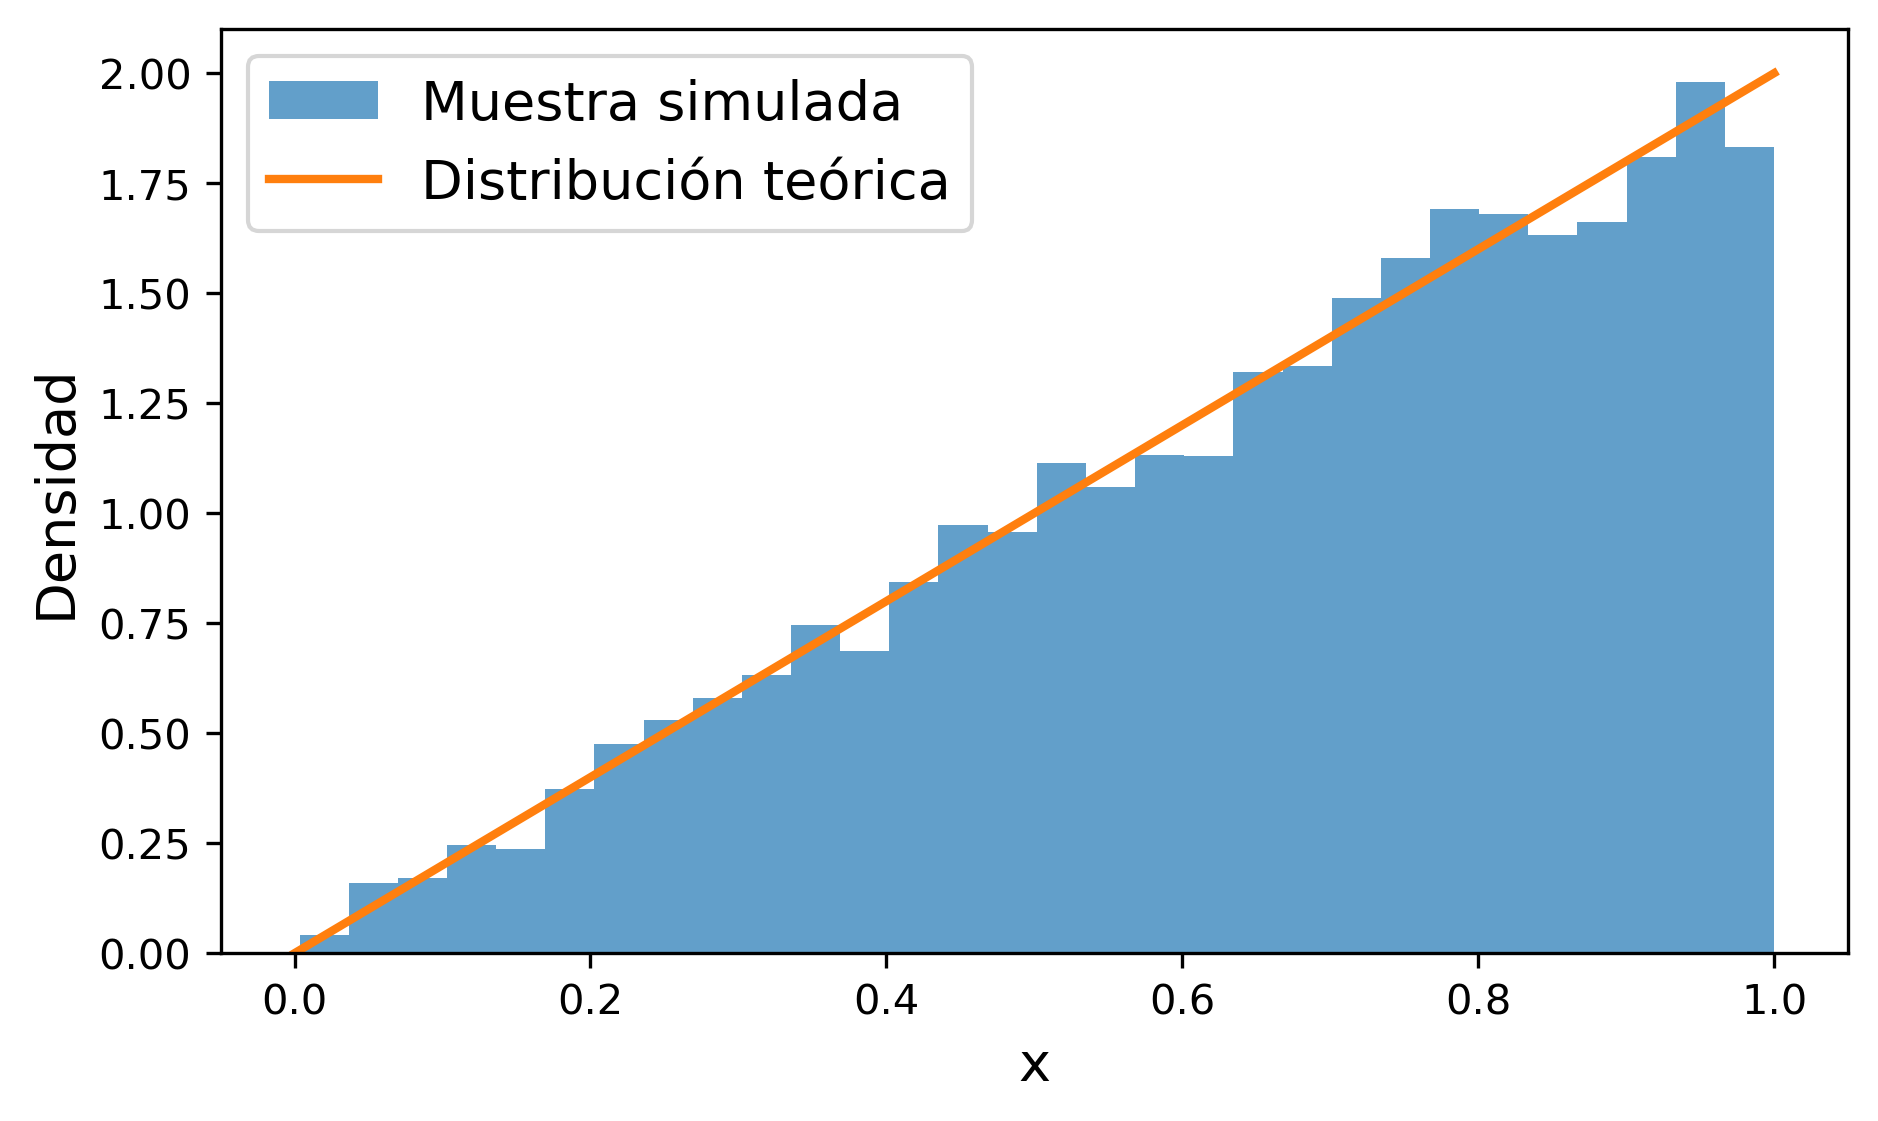

In [12]:
# Completa aquí la visualización y comparación con la distribución teórica
#comprobación visual
x_teorico = np.linspace(0, 1, 500) #para que los valores sean de 0 a 1, porque en ejercicio anterior x=[1,10]
p_teorica = 2*x_teorico #C=1, ya está constante normalizadora

plt.figure(figsize=(7, 4))

plt.hist(x_ejercicio, bins=30, density=True, alpha=0.7, label="Muestra simulada")
plt.plot(x_teorico, p_teorica, linewidth=2, label="Distribución teórica")

plt.xlabel("x")
plt.ylabel("Densidad")
plt.legend()
plt.show()

### Parte C
Una vez que tengas `x_ejercicio`:
- construye un histograma normalizado (arriba)
- superpone la densidad teórica $p(x)=2x$
- identifica dónde se concentran más realizaciones: Ahora las realizaciones se concentran más hacia la derecha que es donde está el máximo como raiz de 1.
- explica brevemente si el resultado coincide con lo esperado, si coincide porque como u = raiz(x) el u inicial es 0 y el u final es 1.

## Conclusión

Antes de usar una distribución simulada en un problema científico conviene comprobar al menos dos cosas:

1. que las muestras se encuentren en el rango esperado
2. que la distribución simulada sea consistente con la distribución teórica


<h2 style="color:fuchsia; font-family:; text-align:center;font-size:20px">
  ❁۪ ｡˚ Mapa general  ❁۪ ｡˚
</h2>
<h2 style="color:fuchsia; font-family:; text-align:center;font-size:15px">
  (1) Población inicial: IMF+SFR ❁۪ ｡˚
</h2>
<h2 style="color:fuchsia; font-family:; text-align:center;font-size:15px">
  (2) Evolución estelar: Main seq., White Dwarf, Neutron Star, Black hole ❁۪ ｡˚
</h2>
<h2 style="color:fuchsia; font-family:; text-align:center;font-size:15px">
  (3) Evolución química: Closed box ❁۪ ｡˚
</h2>
<h2 style="color:fuchsia; font-family:; text-align:center;font-size:15px">
  (4) Observacional: MDF (Metallicity Distribution Function) + G dwarf problem ❁۪ ｡˚
</h2>

<h2 style="color:fuchsia; font-family:; text-align:center;font-size:20px">
  ❁۪ ｡˚ ¿Hasta qué punto un modelo simple de síntesis de población y evolución química puede reproducir las propiedades de la población estelar de la Vía Láctea, y dónde comienza a fallar?  ❁۪ ｡˚
</h2>

In [13]:
#Construccion de población estelar sintética por IMF y SFH

<h2 style="color:fuchsia; font-family:; text-align:center;font-size:17px">
  ❁۪ ｡˚ Parte I: Población sintética mediante Monte Carlo  ❁۪ ｡˚
</h2>
Para la función inicial de masa de Kroupa se utiliza multiple-part power-law IMF (see Kroupa 2001b for details),
epsilon(j) proporcional a m^{-alpha_i}.

La IMF es una distribución segmentada tipo power law, por lo que las masas no pueden generarse uniformemente.
M_initial  ~  IMF_Kroupa
U  ~  U(0,1)    →    M_initial = F_M⁻¹(U) , por tramos

Por Kroupa 2001, bajo 0.08 Masas solares el rango de confianza no está bien determinado. Pero se usan los coeficientes para determinada masa

- a_0 = 0.3 +- 0.7, 0.01<= m/Msun < 0.08
- a_1 = 1.3 +- 0.5, 0.08<= m/Msun < 0.50
- a_2 = 2.3 +- 0.3, 0.50<= m/Msun < 1.00
- a_3 = 2.3 +- 0.7, 1.00 <= m/Msun


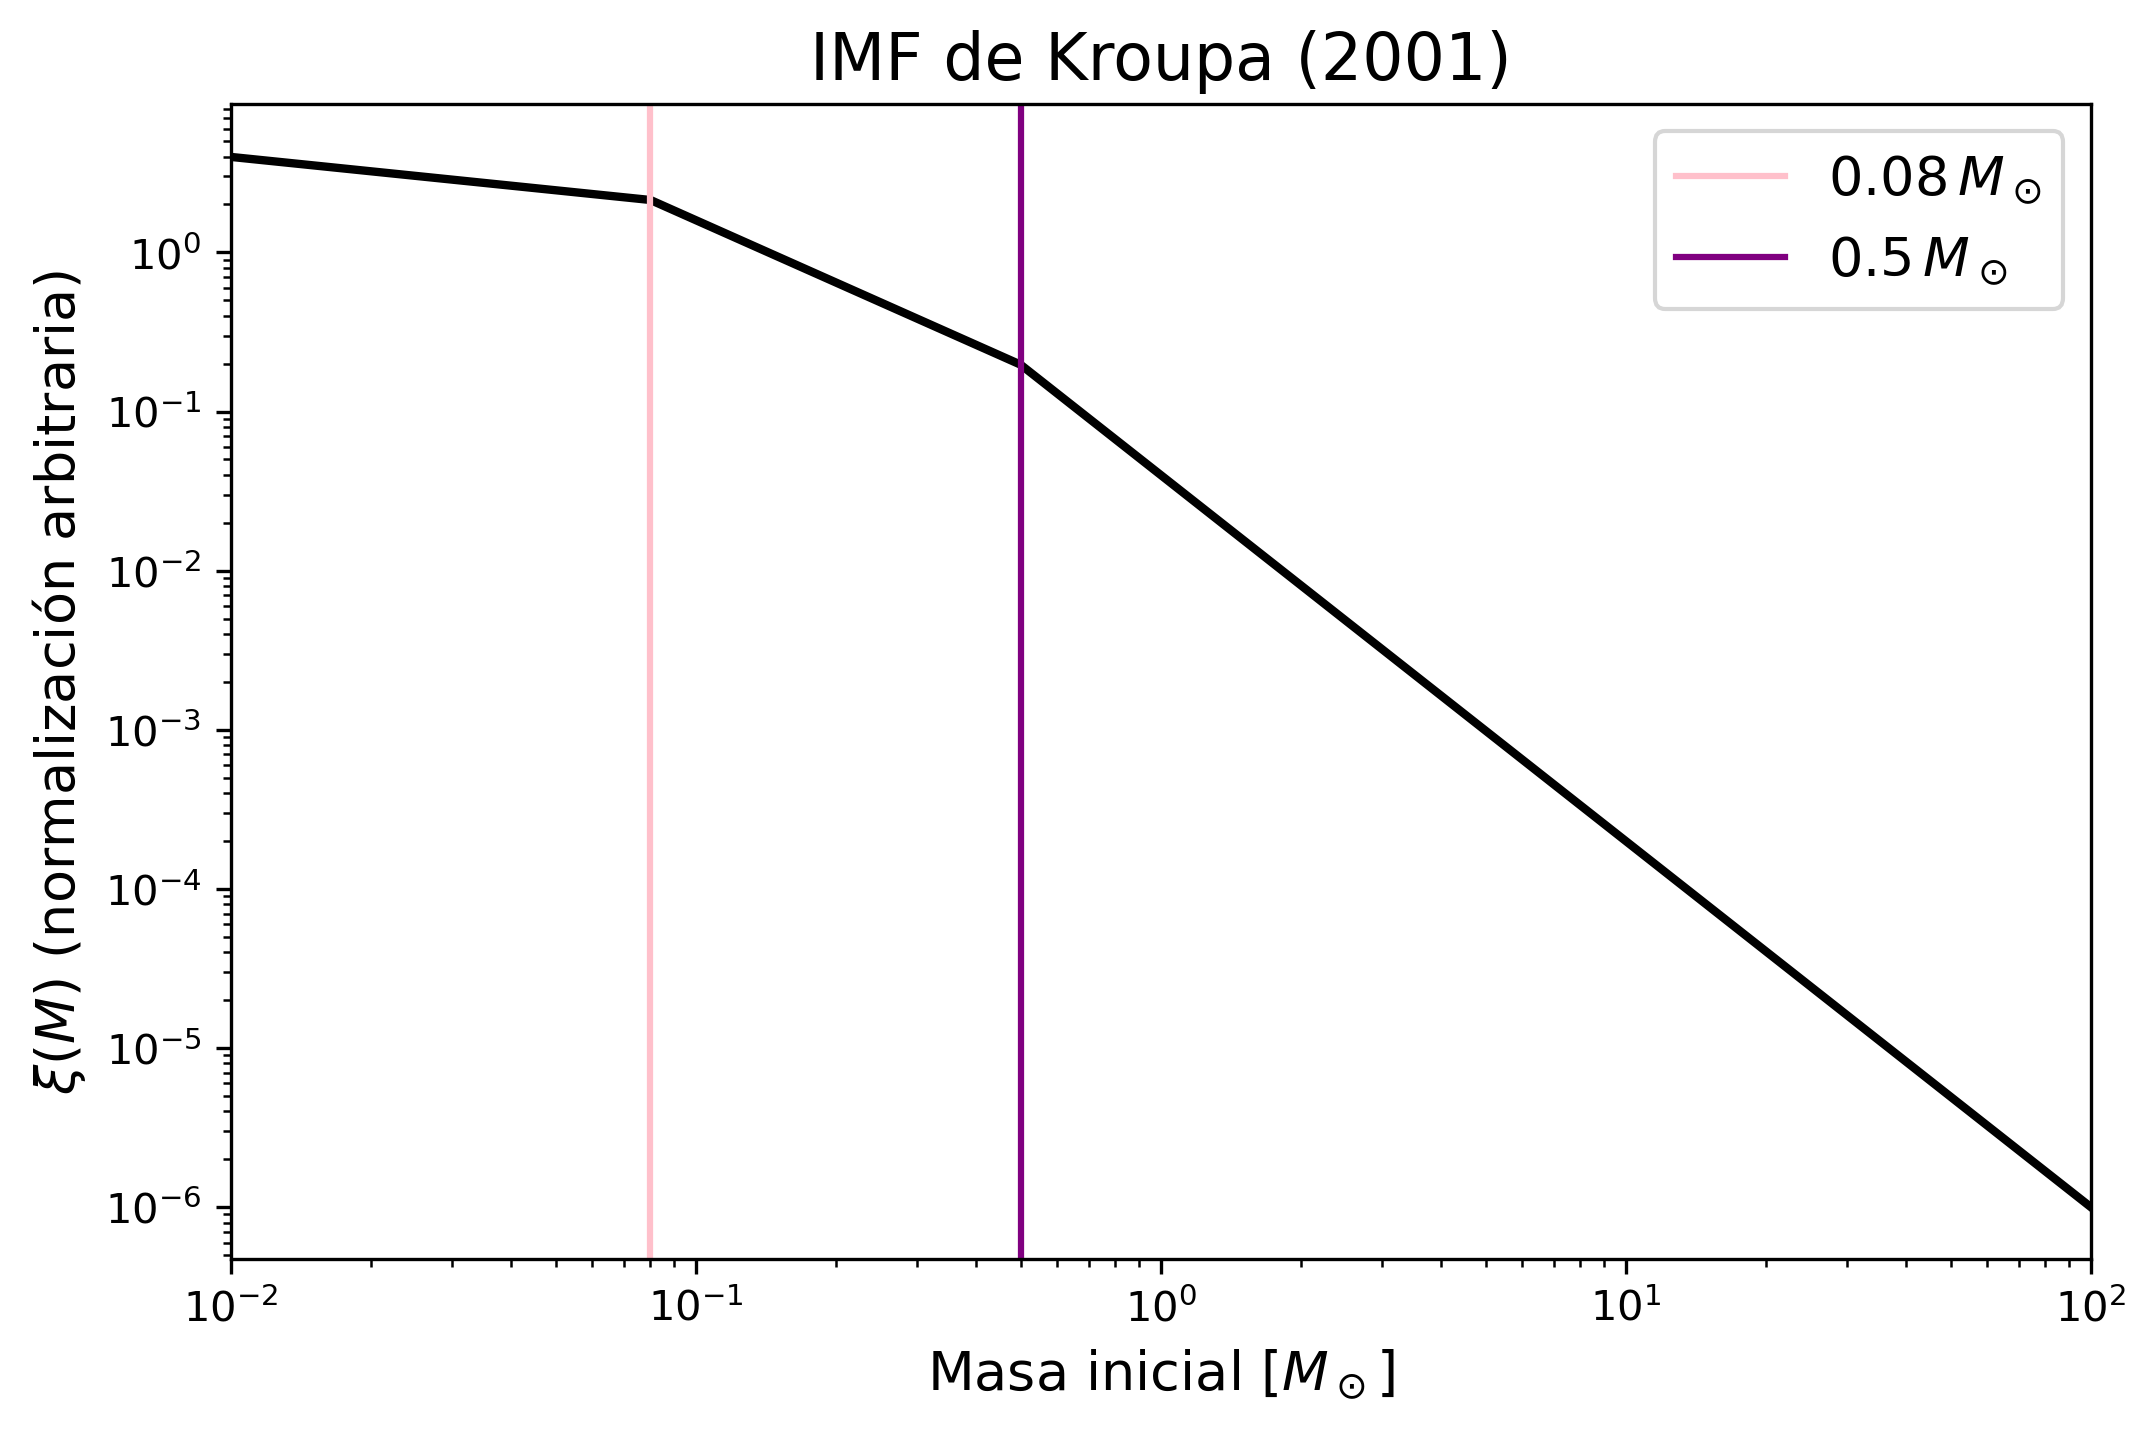

In [30]:
import numpy as np
import matplotlib.pyplot as plt

m = np.logspace(-2, 2, 1000)  # 0.01 a 100 masas solares

# IMF de Kroupa (2001), proporcional a M^(-alpha)
imf = np.piecewise(
    m,
    [m < 0.08, (m >= 0.08) & (m < 0.5), m >= 0.5],
    [
        lambda m: m**(-0.3),
        lambda m: 0.08**(1.3-0.3) * m**(-1.3),
        lambda m: 0.08**(1.3-0.3) * 0.5**(2.3-1.3) * m**(-2.3)
    ]
)

plt.figure(figsize=(8, 5))
plt.plot(m, imf, color="black", linewidth=2)

plt.axvline(0.08, color="pink", linestyle="-", label=r"$0.08\,M_\odot$")
plt.axvline(0.5, color="purple", linestyle="-", label=r"$0.5\,M_\odot$")

plt.xscale("log")
plt.yscale("log")
plt.xlim(0.01, 100)
plt.xlabel(r"Masa inicial [$M_\odot$]")
plt.ylabel(r"$\xi(M)$ (normalización arbitraria)")
plt.title("IMF de Kroupa (2001)")
plt.legend()
plt.show()

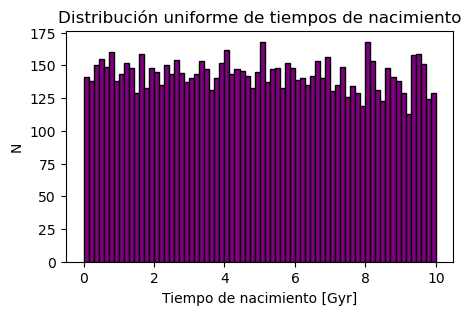

In [2]:
import numpy as np
import matplotlib.pyplot as plt
#Aqui no incluye el menor a 0.08
np.random.seed(42)
N = 30000

def mckroupa(n_estrellas, m_min=0.01, m_max=100.0,
             edad_galaxia=10.0):

    tiempos_nacimiento = np.random.uniform(
        0, edad_galaxia, n_estrellas
    )

    # Límites sin 0.08
    limites = np.array([m_min, 0.50, 1.00, m_max])
    alpha = np.array([1.3, 2.3, 2.3])

    # Normalización continua entre tramos
    constantes = np.ones(3)

    for i in range(1, 3):
        constantes[i] = (
            constantes[i-1]
            * limites[i]**(alpha[i] - alpha[i-1])
        )

    # Probabilidades de cada tramo
    pesos = np.zeros(3)

    for i in range(3):
        lo, hi = limites[i], limites[i+1]
        a = alpha[i]

        integral = (
            hi**(1-a) - lo**(1-a)
        ) / (1-a)

        pesos[i] = constantes[i] * integral

    probabilidades = pesos / pesos.sum()

    tramos = np.random.choice(
        3, size=n_estrellas, p=probabilidades
    )

    masas = np.empty(n_estrellas)

    # Muestreo inverso
    for i in range(3):
        mask = tramos == i
        n = mask.sum()

        if n == 0:
            continue

        lo, hi = limites[i], limites[i+1]
        a = alpha[i]
        u = np.random.uniform(0, 1, n) #para validar numéricamente

        masas[mask] = (
            lo**(1-a)
            + u * (hi**(1-a) - lo**(1-a))
        )**(1/(1-a))

    return masas, tiempos_nacimiento
# Simulación
mmin = 0.01
mmax = 100.0
galaxy_age = 10.0

masas_simuladas, tiempos_simulados = mckroupa(
    N, mmin, mmax, galaxy_age
)

# Histograma de tiempos de nacimiento
plt.figure(figsize=(5, 3))
plt.hist(
    tiempos_simulados,
    bins=70,
    color="purple",
    edgecolor="black"
)
plt.xlabel("Tiempo de nacimiento [Gyr]")
plt.ylabel("N")
plt.title("Distribución uniforme de tiempos de nacimiento")

plt.show()

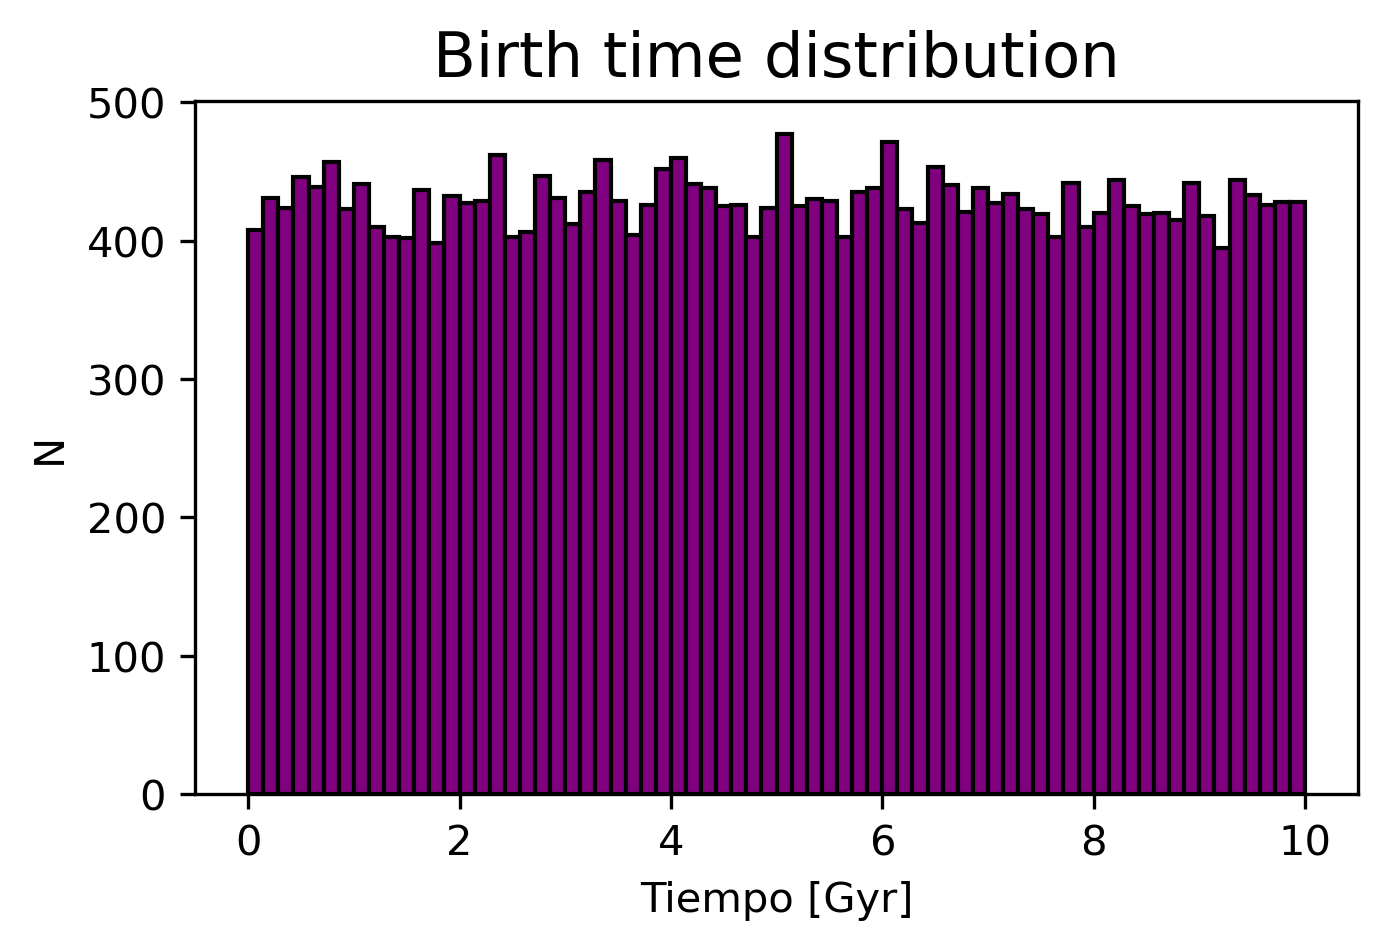

In [351]:
#aqui si incluye 0.08
np.random.seed(42)
N = 30000
def mckroupa(n_estrellas, m_min=0.01, m_max=100.0, edad_galaxia=10.0):
    tiempos_nacimiento = np.random.uniform(0, edad_galaxia, n_estrellas) #tiempo uniforme
    limites = np.array([m_min, 0.08, 0.50, 1.00, m_max]) #masas limite para cada tramo
    alpha = np.array([0.3, 1.3, 2.3, 2.3]) #exponentes de acuerdo a Kroupa 2001
    #pesos y normalización 
    constantes = np.zeros(4)
    constantes[0] = 1.0
    for i in range(1, 4):
        constantes[i] = (constantes[i-1]* limites[i]**(alpha[i] - alpha[i-1]))
    pesos = np.zeros(4)
    for i in range(4):
        lo, hi = limites[i], limites[i+1]
        a = alpha[i]
        if np.isclose(a, 1.0):
            integral = np.log(hi / lo)
        else:
            integral = (
                hi**(1-a) - lo**(1-a)
            ) / (1-a)

        pesos[i] = constantes[i] * integral

    probabilidades = pesos / pesos.sum() #prob. para cada tramo
    tramos = np.random.choice(4, size=n_estrellas, p=probabilidades)
    masas = np.empty(n_estrellas)
    # Muestreo invers de la distribución de potencia
    for i in range(4):
        mask = tramos == i
        n = mask.sum()

        if n == 0:
            continue

        lo, hi = limites[i], limites[i+1]
        a = alpha[i]
        u = np.random.uniform(0, 1, n)

        if np.isclose(a, 1.0):
            masas[mask] = lo * (hi / lo)**u
        else:
            masas[mask] = (lo**(1-a)+ u * (hi**(1-a) - lo**(1-a)))**(1/(1-a))

    return masas, tiempos_nacimiento

mmin=0.01
mmax=100.0
galaxy_age=10 #Gyr
masas_simuladas, tiempos_simulados = mckroupa(N,mmin, mmax, galaxy_age)
plt.figure(figsize=(5,3))
plt.hist(tiempos_simulados, bins=70,color="purple", edgecolor="black")
plt.xlabel("Tiempo [Gyr]",fontsize=10)
plt.ylabel("N",fontsize=10)
plt.title("Birth time distribution",fontsize=15)
plt.show()

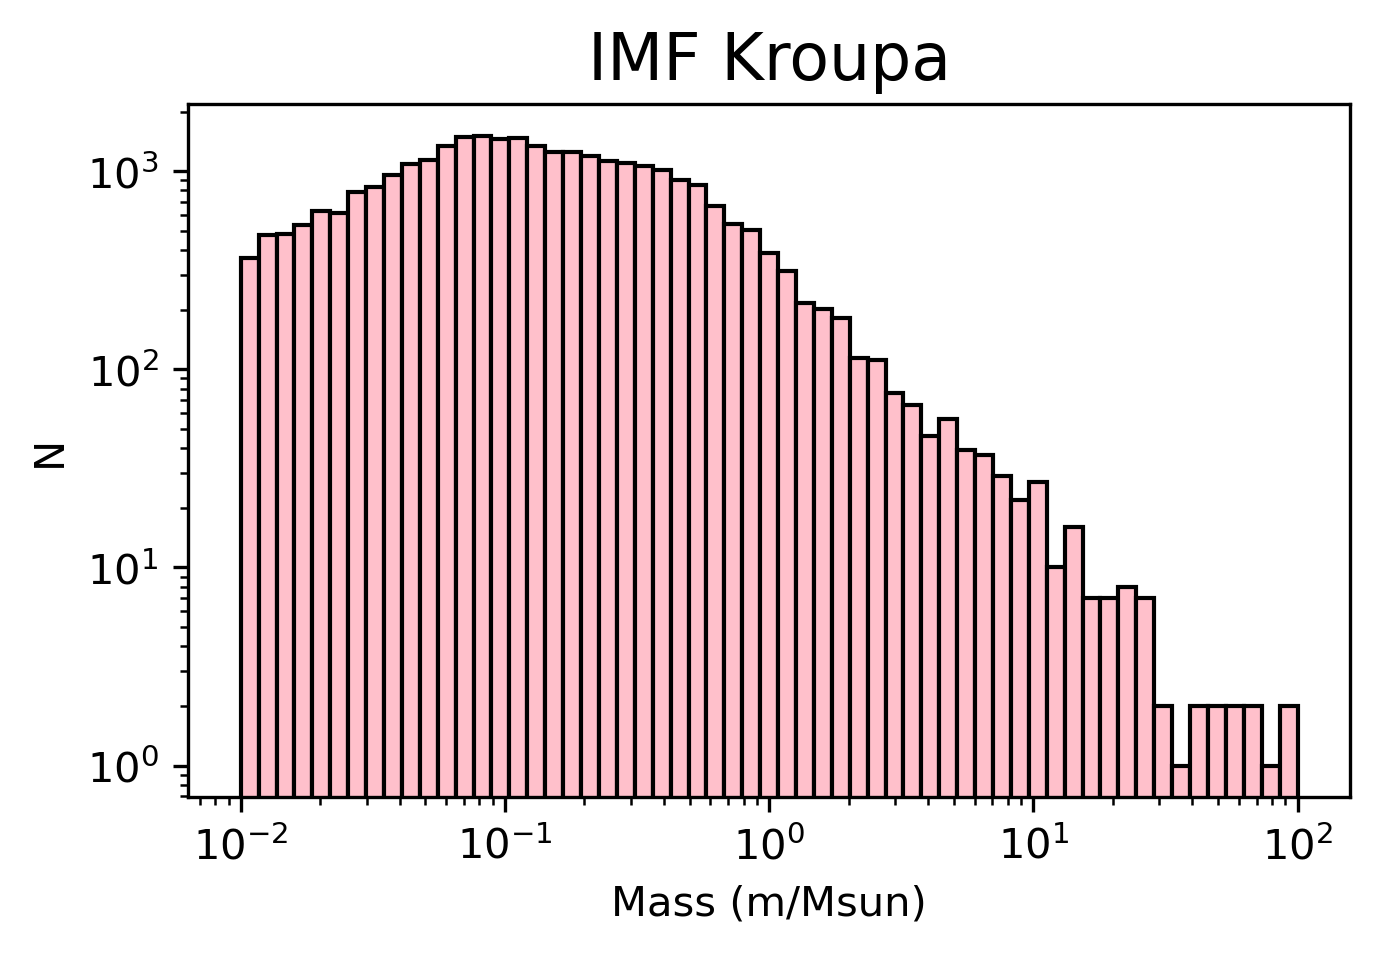

In [352]:
#masas con incluir 0.08
bins = np.logspace(np.log10(0.01), np.log10(100), 60)
plt.figure(figsize=(5,3))
plt.hist(masas_simuladas, bins=bins,color="pink", edgecolor="black")
plt.xlabel("Mass (m/Msun)",fontsize=10)
plt.ylabel("N",fontsize=10)
plt.xscale("log")
plt.yscale("log")
plt.title("IMF Kroupa")
plt.show()

Implemente un método de muestreo apropiado para la IMF, por ejemplo transformación inversa por segmentos (eso es para kroupa porque se define a través de intervalos de masa)
Explique cómo se normalizan las probabilidades asociadas a cada segmento
Valide numéricamente que la muestra generada reproduce la forma de la IMF (como ejemplo de profe validar que den entre 0 y 1 valores


<h2 style="color:fuchsia; font-family:; text-align:center;font-size:17px">
  ❁۪ ｡˚ SFH y tMS ❁۪ ｡˚
</h2>


In [353]:
np.random.seed(42)
N = 30000
T_MW = 10  # Gyr

masas, t_birth = mckroupa(
    N, m_min=0.01, m_max=100, edad_galaxia=T_MW
)

t_age = T_MW - t_birth

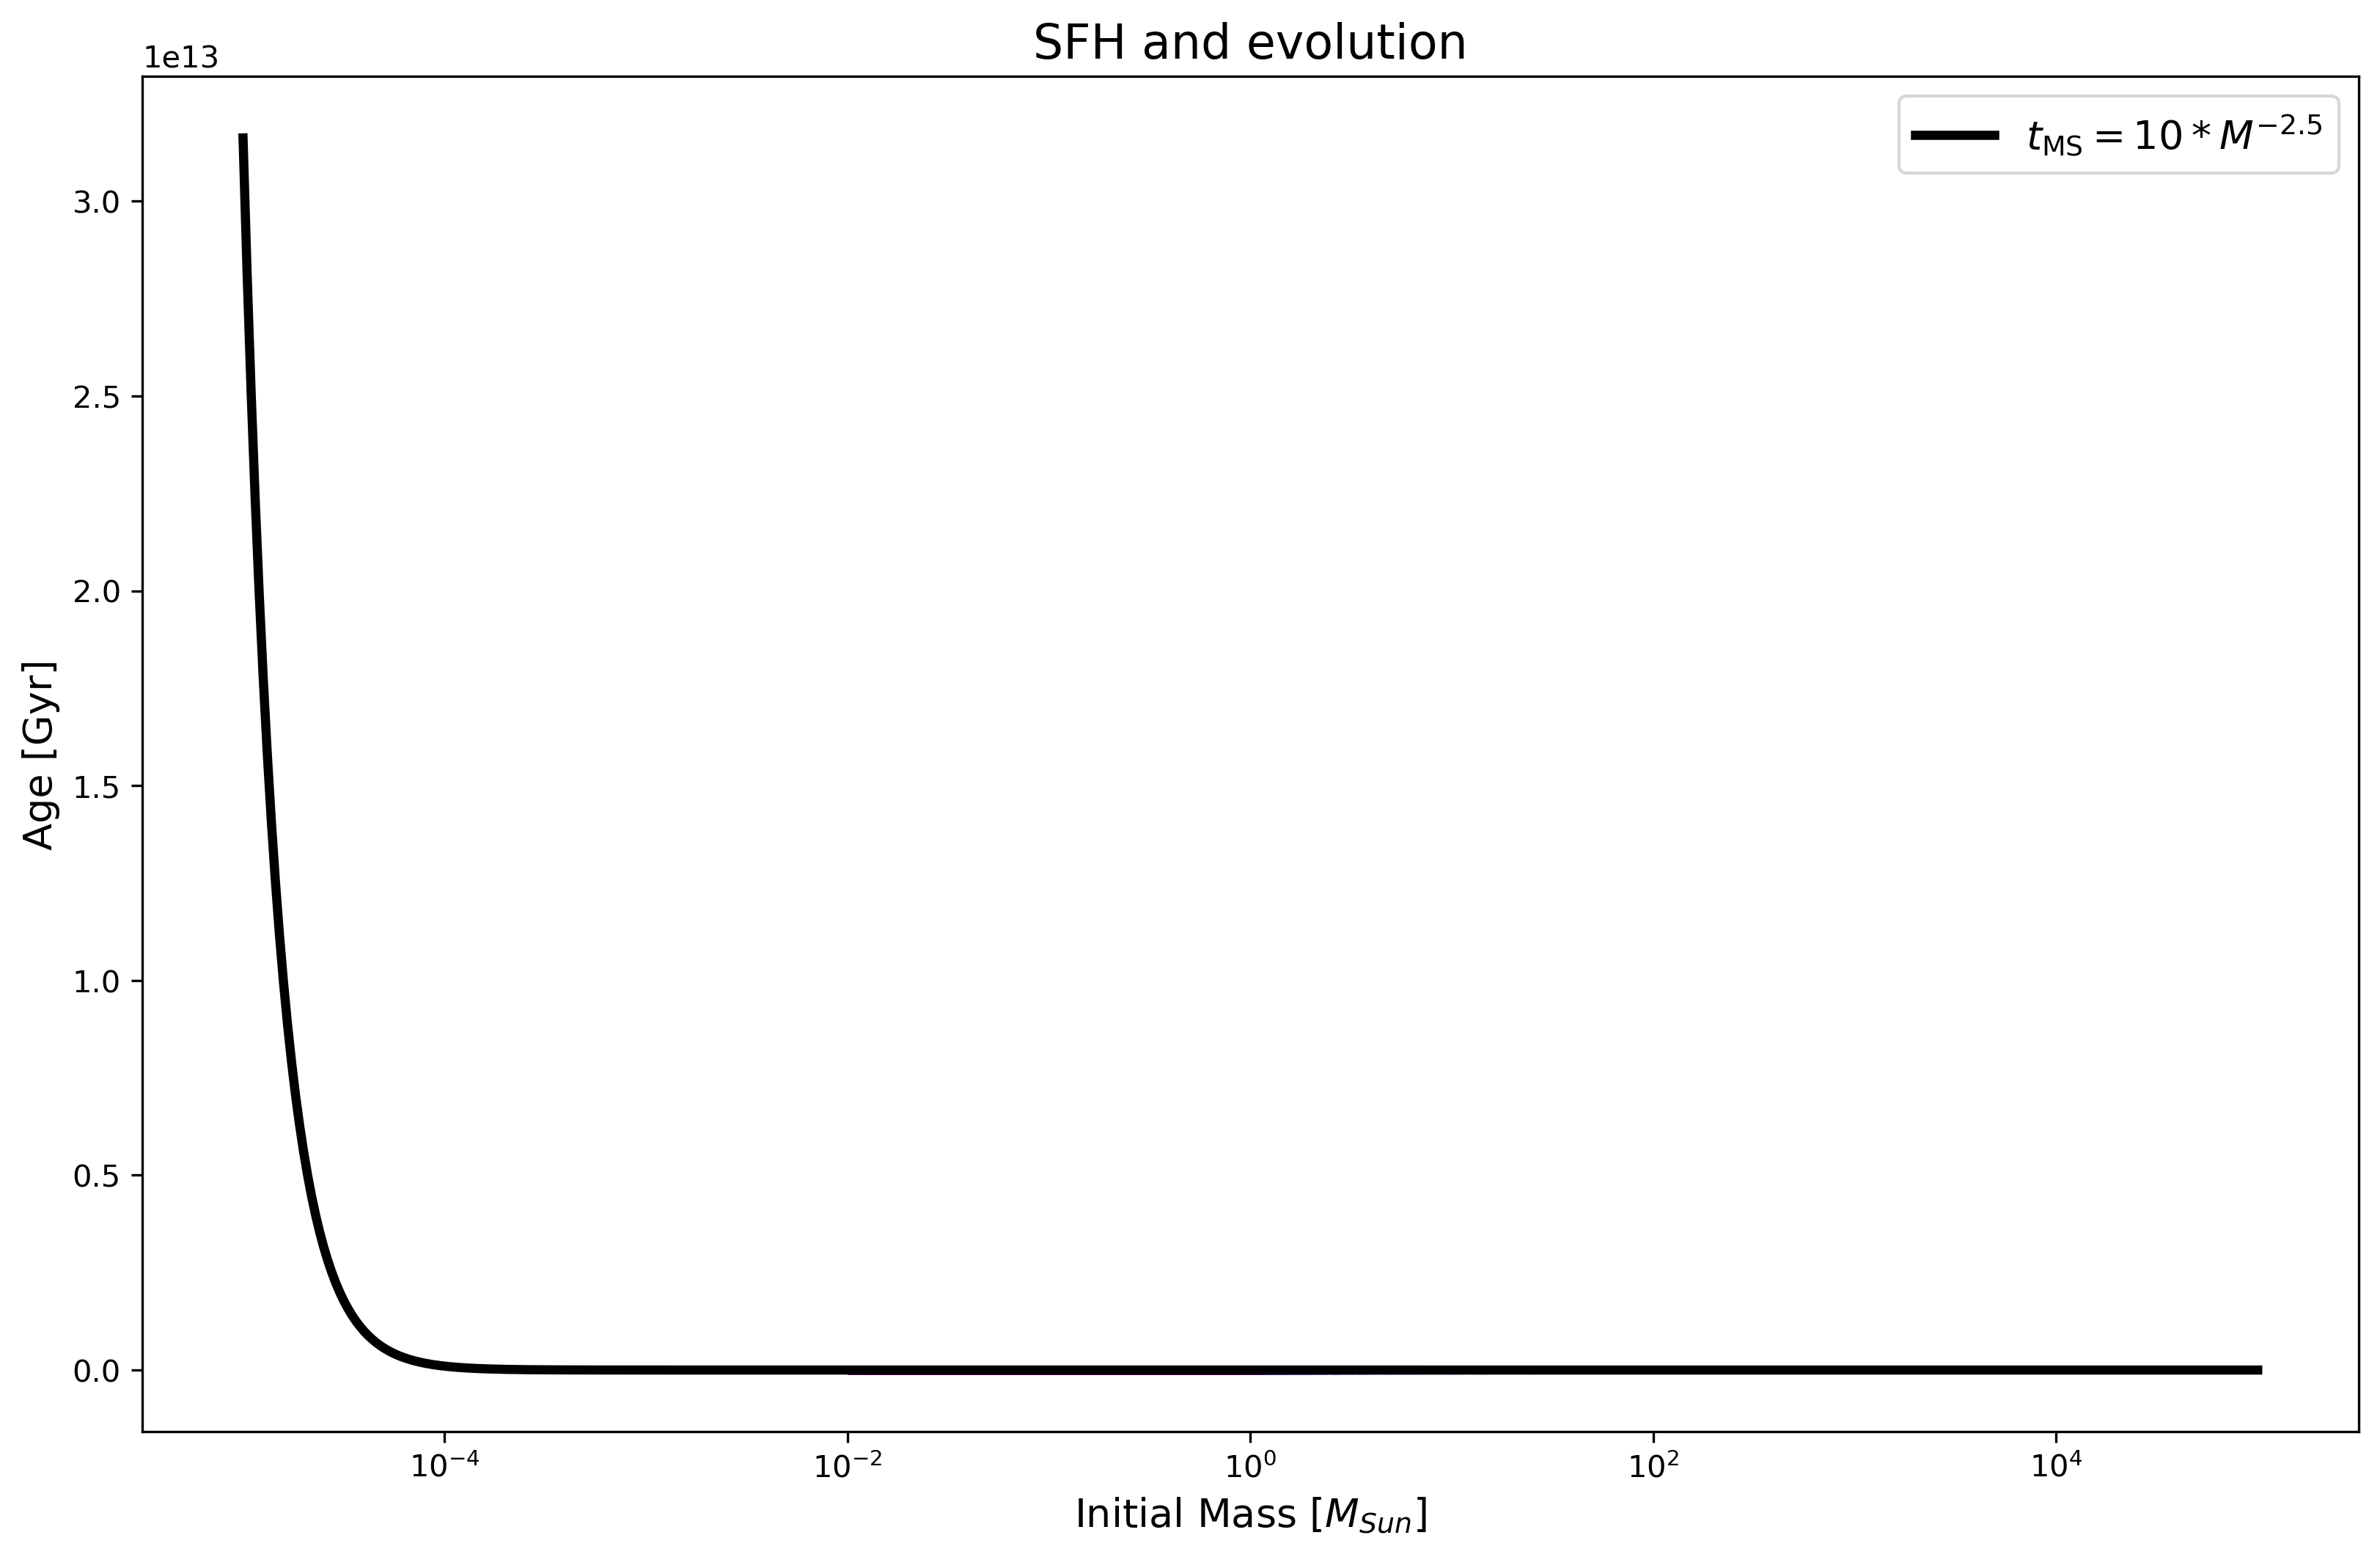

In [354]:
#primero distribución uniforme para SFH usando lo de Kroupa
np.random.seed(42) #registrada para permitir reproducibilidad
N = 30000
T_MW=10  #Gyr
mmin=0.01
mmax=100
#datos y distribución para edad nacimiento de 0 a 10 Gyr
masas, t_birth = mckroupa(N, m_min=0.01, m_max=100, edad_galaxia=T_MW)
t_age=T_MW - t_birth # Edad actual de cada estrella
t_MS=10*(masas**(-2.5)) #tiempo en MS Gyr
#condiciones para que estrella sea clasificada puede ser simple la clasificación
ms=t_age<t_MS
remnant=t_age>=t_MS
masa_definido=np.logspace(-5, 5, 500)
tiempo=10*masa_definido**(-2.5) #este tiempo ms en Gyr
plt.figure(figsize=(13, 8))
plt.plot(masa_definido, tiempo, color="black",linewidth=3, label=r"$t_{\rm MS}=10*M^{-2.5}$")
plt.scatter(masas[ms], t_age[ms], s=3,alpha=0.25, color="purple") #el usar [] se debe al utilizar dato asignado a la variable
plt.scatter(masas[remnant], t_age[remnant], s=3,alpha=0.25, color="blue")
plt.xscale("log")
#plt.xlim(0.1, 100)
#plt.ylim(0, T_MW)
plt.xlabel(r"Initial Mass [$M_{Sun}$]")
plt.ylabel("Age [Gyr]")
plt.title("SFH and evolution")
plt.legend()
plt.show()

In [355]:
#total todo, ms, postms
N, np.sum(ms), np.sum(remnant)

(30000, 28832, 1168)

In [356]:
#las que son ms y remnant
np.mean(ms), np.mean(remnant)

(0.9610666666666666, 0.038933333333333334)

Las estrellas en zona interior son de secuencia principal, y estrellas desde aproximadamente 100 masas solar como masa inicial con edades variadas son remanentes. Luego hay muchas estrellas en secuencia principal!! 

<h2 style="color:fuchsia; font-family:; text-align:center;font-size:17px">
  ❁۪ ｡˚ Remanentes estelares e Initial–Final Mass Relations ❁۪ ｡˚
</h2>
Para las estrellas que han abandonado la secuencia principal, determine el tipo de remanente y su masa final utilizando relaciones inicial–final de la literatura.
White dwarfs: Miller et al. (2026), Full Sample Fit 1, Eqs. 6–9

Neutron stars y black holes: Raithel, Sukhbold & Özel (2018), siguiendo las secciones y ecuaciones indicadas para cada canal de remanente
Para black holes, mantenga explícitos los parámetros del modelo adoptado, incluyendo la fracción de eyección si corresponde
Documente los rangos de masa de validez y cualquier decisión adoptada en las transiciones entre prescripciones


In [357]:
#para WD se tienen 4 ecuaciones
np.random.seed(42)
tipo_remanente = np.full(len(masas), "Sin asignar", dtype=object)
masa_final = np.full(len(masas), np.nan)
canal = np.full(len(masas), "Fuera de rango", dtype=object)
def masa_WD(Mi):
    if 0.84 <= Mi < 1.98:
        return 0.160 * Mi + 0.394
    elif 1.98 <= Mi < 2.33:
        return -0.155 * Mi + 1.015
    elif 2.33 <= Mi < 3.98:
        return 0.174 * Mi + 0.251
    elif 3.98 <= Mi < 8.39:
        return 0.075 * Mi + 0.644
    return np.nan

In [358]:
#BH
f_ej = 0.90       #Fracción de envoltura eyectada para BH
def masa_BH(Mi, f_ej=0.90):
    if not 0.0 <= f_ej <= 1.0:
        raise ValueError("f_ej debe estar entre 0 y 1.")
    if 15.0 <= Mi <= 40.0:
        M_core = Mi*0.4130-2.024
        x = Mi - 21.872
        M_all = 0.003112 * x**3- 0.05973 * x**2+0.00694 * x+16.28
        return f_ej * M_core + (1.0 - f_ej) * M_all

    # Branch II: 45 <= M_ZAMS <= 120 Msun
    elif 45.0 <= Mi <= 120.0:
        return 5.795 + 1.007e9 * Mi**(-4.926)

    # No extrapolar fuera de las ramas
    return np.nan


In [359]:
R_NS_km = 12.0   #radio característico neutron star
#NS RAITHEL ET AL. (2018), EQS. 10-15
def masa_NS_barionica(Mi):
    # Branch I
    if 9.0 <= Mi <= 13.0:
        x = Mi - 14.75
        return (
            2.24 + 0.508*x
            + 0.125*x**2
            + 0.0110*x**3
        )

    # Branch II
    elif 13.0 < Mi < 15.0:
        return 0.123 + 0.112 * Mi

    # Branch III
    elif 15.0 <= Mi < 17.8:
        return 0.996 + 0.0384 * Mi

    # Branch IV
    elif 17.8 < Mi < 18.5:
        return -0.020 + 0.10 * Mi

    # Branch V: distribución gaussiana
    elif 18.5 <= Mi < 21.7:
        return np.random.normal(1.60, 0.155)

    # Branch VII: distribución gaussiana
    elif 60.0 <= Mi <= 120.0:
        return np.random.normal(1.78, 0.016)

    # Branch VI (25.2 <= Mi < 27.5):
    # Se deja sin asignar hasta verificar la expresión
    # polinómica de la fuente original y su transcripción.
    return np.nan

In [360]:
#CONVERSION NS: MASA BARIONICA -> GRAVITACIONAL
# Raithel et al. (2018), Eqs. 19-20
G = 6.67430e-11
M_SUN = 1.98847e30
C = 299792458.0
R_NS = R_NS_km * 1000.0

def masa_NS_gravitacional(Mb):
    if not np.isfinite(Mb) or Mb <= 0:
        return np.nan
    # Resolver Mb = Mg + BE(Mg) por bisección
    # beta = G*Mg*M_sun/(R_NS*c^2)
    lo, hi = 0.0, Mb
    for _ in range(100):
        Mg = 0.5 * (lo + hi)
        beta = G * (Mg * M_SUN) / (R_NS * C**2)
        BE = Mg * (0.6 * beta / (1.0 - 0.5 * beta))
        Mb_calculada = Mg + BE

        if Mb_calculada > Mb:
            hi = Mg
        else:
            lo = Mg

    return 0.5 * (lo + hi)
# Fracción de resultados NS para el motor W18
# Raithel et al. (2018), Table 2
def prob_NS(Mi):
    if 9.0 <= Mi < 15.0:
        return 1.0
    elif 15.0 <= Mi < 17.8:
        return 0.679
    elif 17.8 < Mi < 18.5:
        return 0.833
    elif 18.5 <= Mi < 21.7:
        return 0.500
    elif 25.2 <= Mi < 27.5:
        return 0.652
    elif 60.0 <= Mi <= 120.0:
        return 0.400
    return 0.0

In [361]:
#ahora para cada estrella con masa específica definida 
#por la variable de remanente 
for i in np.where(remnant)[0]:
    Mi = masas[i] #para contabilizacion de cada masa
    if 0.84 <= Mi < 8.39: #Rango por Miller como masas válidas
        Mf = masa_WD(Mi)
        if np.isfinite(Mf):
            tipo_remanente[i] = "WD"
            masa_final[i] = Mf
            canal[i] = "Miller Full Sample Fit 1"
    elif 9.0 <= Mi <= 120.0: #límites rangos de masa para que sean NS y BH
        #Muestreo probabilístico del canal NS
        pns = prob_NS(Mi)
        forma_NS = np.random.random() < pns
        if forma_NS:
            Mb = masa_NS_barionica(Mi)
            Mg = masa_NS_gravitacional(Mb)
            if np.isfinite(Mg):
                tipo_remanente[i] = "NS"
                masa_final[i] = Mg
                canal[i] = "Raithel W18: NS"
        else:
            Mf = masa_BH(Mi, f_ej=f_ej)
            if np.isfinite(Mf):
                tipo_remanente[i] = "BH"
                masa_final[i] = Mf
                canal[i] = f"Raithel BH, f_ej={f_ej:.2f}"
                
for tipo in ["WD", "NS", "BH", "None"]:
    mask = tipo_remanente == tipo #tienen que coincidir
    valores = masa_final[mask]
    valores = valores[np.isfinite(valores)]
    print(f"\n{tipo}:")
    print("Número:", mask.sum())
    if len(valores) > 0:
        print(f"Masa media: {valores.mean():.3f} Msun")
        print(f"Masa mínima: {valores.min():.3f} Msun")
        print(f"Masa máxima: {valores.max():.3f} Msun")


WD:
Número: 1051
Masa media: 0.750 Msun
Masa mínima: 0.555 Msun
Masa máxima: 1.258 Msun

NS:
Número: 74
Masa media: 1.393 Msun
Masa mínima: 1.243 Msun
Masa máxima: 1.589 Msun

BH:
Número: 28
Masa media: 8.371 Msun
Masa mínima: 5.078 Msun
Masa máxima: 12.842 Msun

None:
Número: 0


In [59]:
len(masas),remnant.sum()

(30000, 2118)

<h2 style="color:fuchsia; font-family:; text-align:center;font-size:17px">
  ❁۪ ｡˚ Parte II: Metallicity distribution in close box model  ❁۪ ｡˚
</h2>

Teniendo una tasa de formación estelar constante hasta 10 Gyr, también las estrellas nacen con metalicidad determinada Z_birth = Z_gas(t_birth). Donde se supone:
- Sistema dominado por gas
- No hay entrada ni salida de gas (closed system)
- Gas se mezcla instantáneamente y homogéneamente
- Rendimiento químico es altamente efectivo y constante.
- Evolución en una sola zona, no hay dependencia espacial.

In [362]:
Z_sun=0.014     #metalicidad incial
T_MW=10.0       #Gyr
mu_f=0.10       #Fracción final de gas

y = Z_sun/np.log(1.0/mu_f) # Yield efectivo para que Z_gas(T_MW) = Z_sun
def mu_gas(t):
    return 1.0-(1.0-mu_f)*t/T_MW #evolución fracción de gas

def Z_gas(t):
    return y*np.log(1.0 / mu_gas(t)) #evolución de la metalicidad del gas
    
Z_birth = Z_gas(t_birth) #Metalicidad en el nacimiento de cada estrella
#Metalicidad logarítmica relativa al Sol
MH_birth = np.log10(Z_birth/Z_sun)
#[M/H] ≈ [Fe/H]. Esta igualdad no es exacta y debe 
#aparecer explícitamente entre las limitaciones del modelo
print("y", y)
print("Mínima [M/H]=[Fe/H]:", np.min(MH_birth))
print("Máxima [M/H]=[Fe/H]:", np.max(MH_birth))
print("Muestra de Z_birth:", Z_birth[:10])
print("Muestra de [M/H]=[Fe/H]:", MH_birth[:10])

y 0.006080122746645525
Mínima [M/H]=[Fe/H]: -5.342213649252215
Máxima [M/H]=[Fe/H]: -0.00012758243786461734
Muestra de Z_birth: [0.0024996  0.01176786 0.00653778 0.00470545 0.00091997 0.00091982
 0.00032645 0.00919389 0.00473467 0.00616575]
Muestra de [M/H]=[Fe/H]: [-0.74825747 -0.07543036 -0.33069796 -0.47352662 -1.18235486 -1.18242735
 -1.63231284 -0.18262855 -0.47083842 -0.35614192]


/var/folders/36/rk32flss4bj4sbk5qc_2v8l00000gn/T/ipykernel_17010/4234131046.py:19: RuntimeWarning: divide by zero encountered in log10
  MH_t = np.log10(Z_gas / Z_sun)


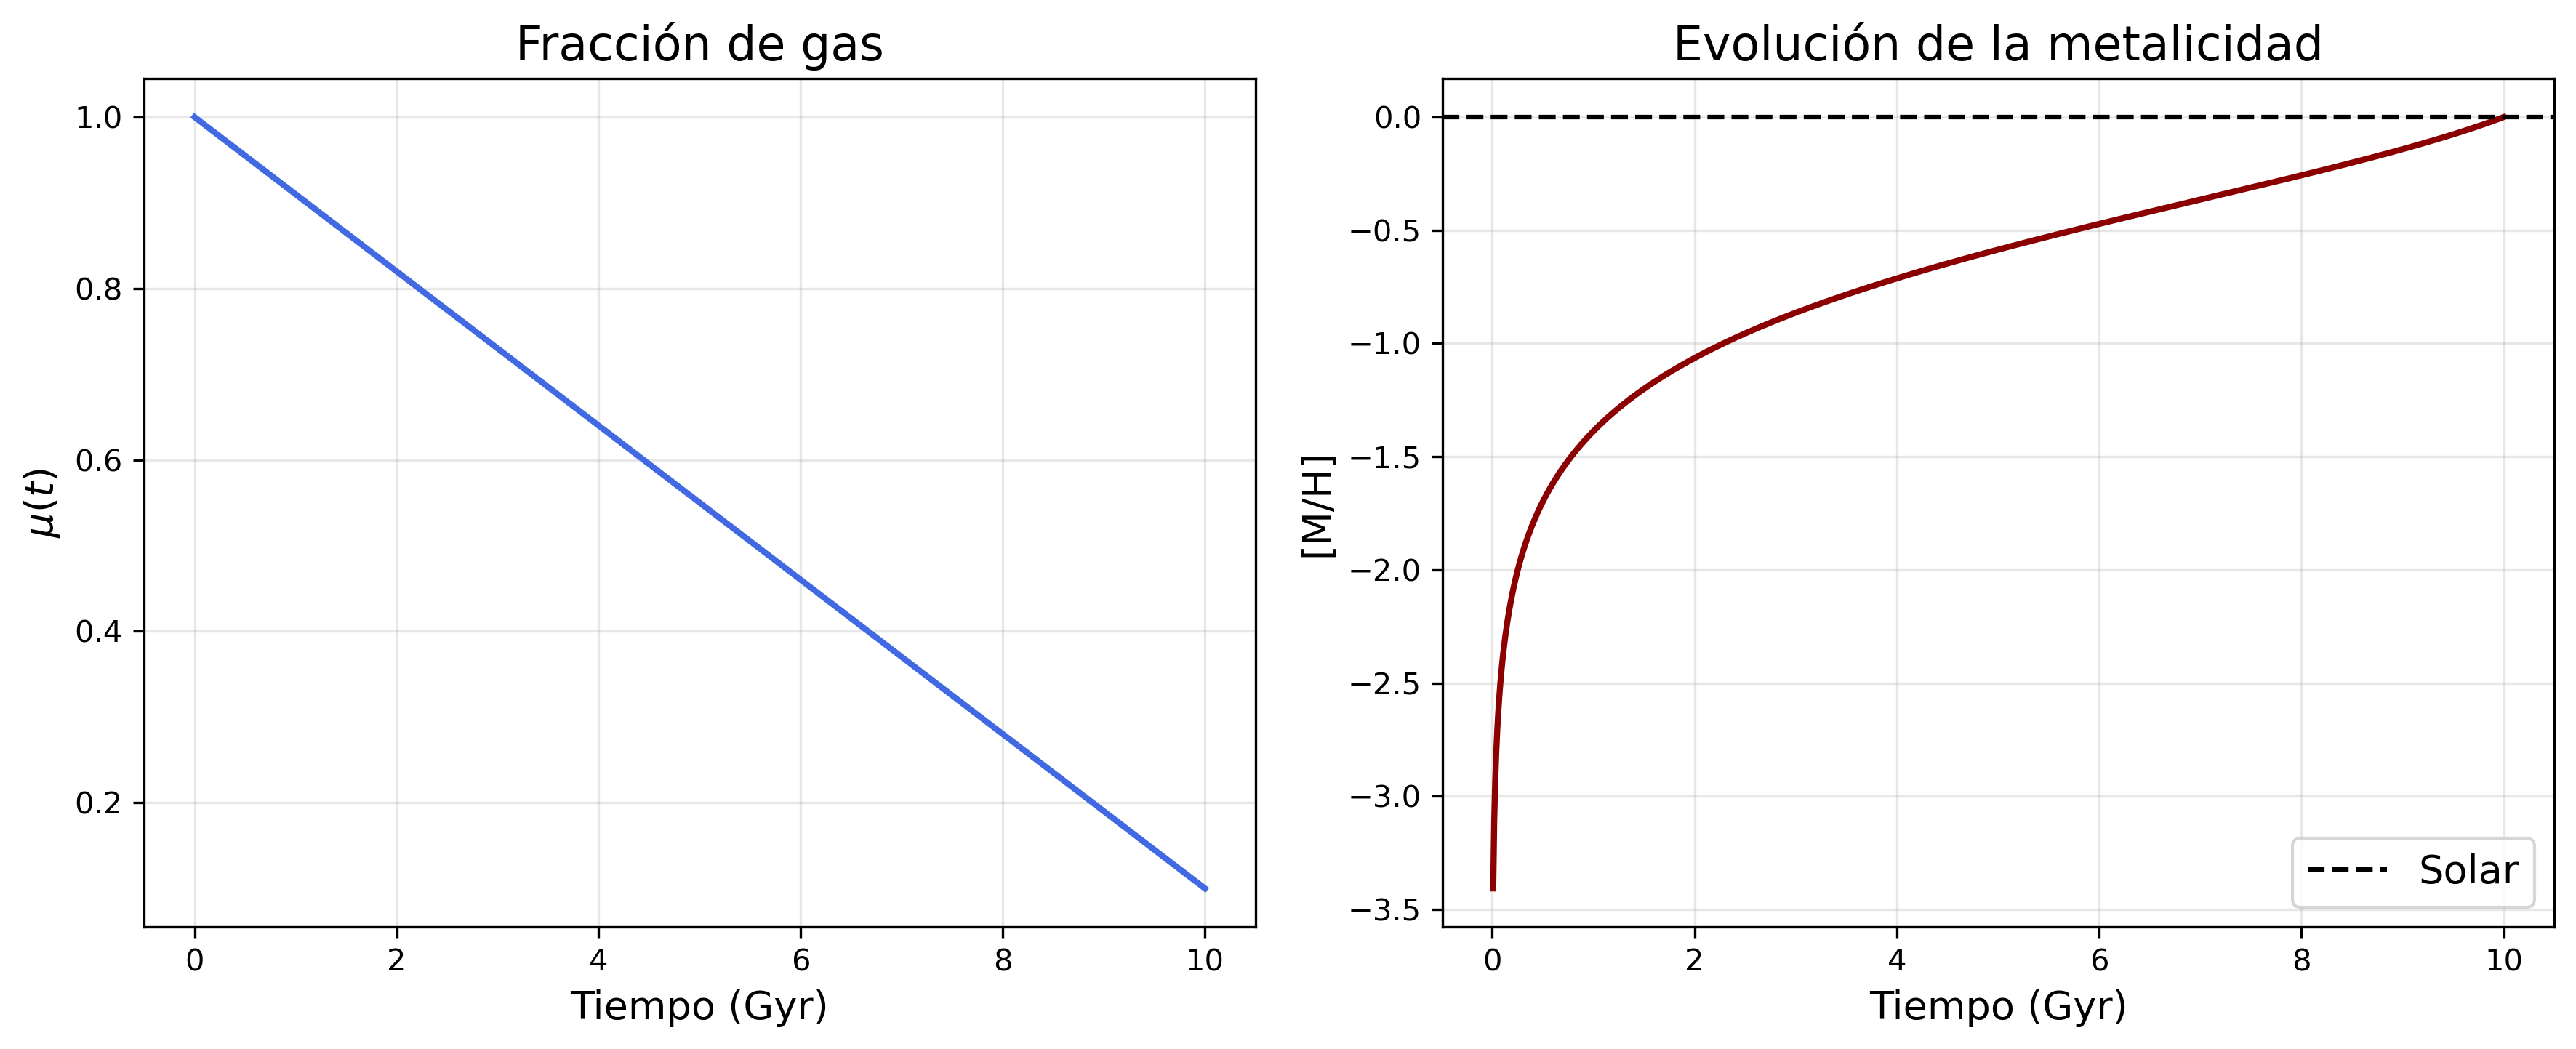

In [363]:
import numpy as np
import matplotlib.pyplot as plt

Z_sun = 0.014

# Tiempo de evolución de la Vía Láctea
t = np.linspace(0, T_MW, 1000)

# Fracción de gas
mu_t = 1.0 - (1.0 - mu_f) * t / T_MW

# Yield efectivo: metalicidad solar al final de la simulación
y = Z_sun / np.log(1.0 / mu_f)

# Metalicidad del gas en función del tiempo
Z_gas = y * np.log(1.0 / mu_t)

# Metalicidad logarítmica relativa al Sol
MH_t = np.log10(Z_gas / Z_sun)
# Gráficas
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(t, mu_t, color="royalblue", linewidth=2)
ax1.set_xlabel("Tiempo (Gyr)")
ax1.set_ylabel(r"$\mu(t)$")
ax1.set_title("Fracción de gas")
ax1.grid(alpha=0.3)

ax2.plot(t, MH_t, color="darkred", linewidth=2)
ax2.axhline(0, color="black", linestyle="--", label="Solar")
ax2.set_xlabel("Tiempo (Gyr)")
ax2.set_ylabel("[M/H]")
ax2.set_title("Evolución de la metalicidad")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Diagnóstico físico;
- Construya y discuta la relación edad-metalicidad producida por el modelo.

- Explique por qué las estrellas que se forman más tarde nacen, en promedio, a mayor metalicidad.

- Identifique qué aspectos de esta relación son consecuencia directa de los supuestos del closed-box model.

<h2 style="color:fuchsia; font-family:; text-align:center;font-size:17px">
  ❁۪ ｡˚ Parte III: Construcción de la población actual ❁۪ ｡˚
</h2>
N = 10², 10³, 10⁴, 10⁵, 10⁶

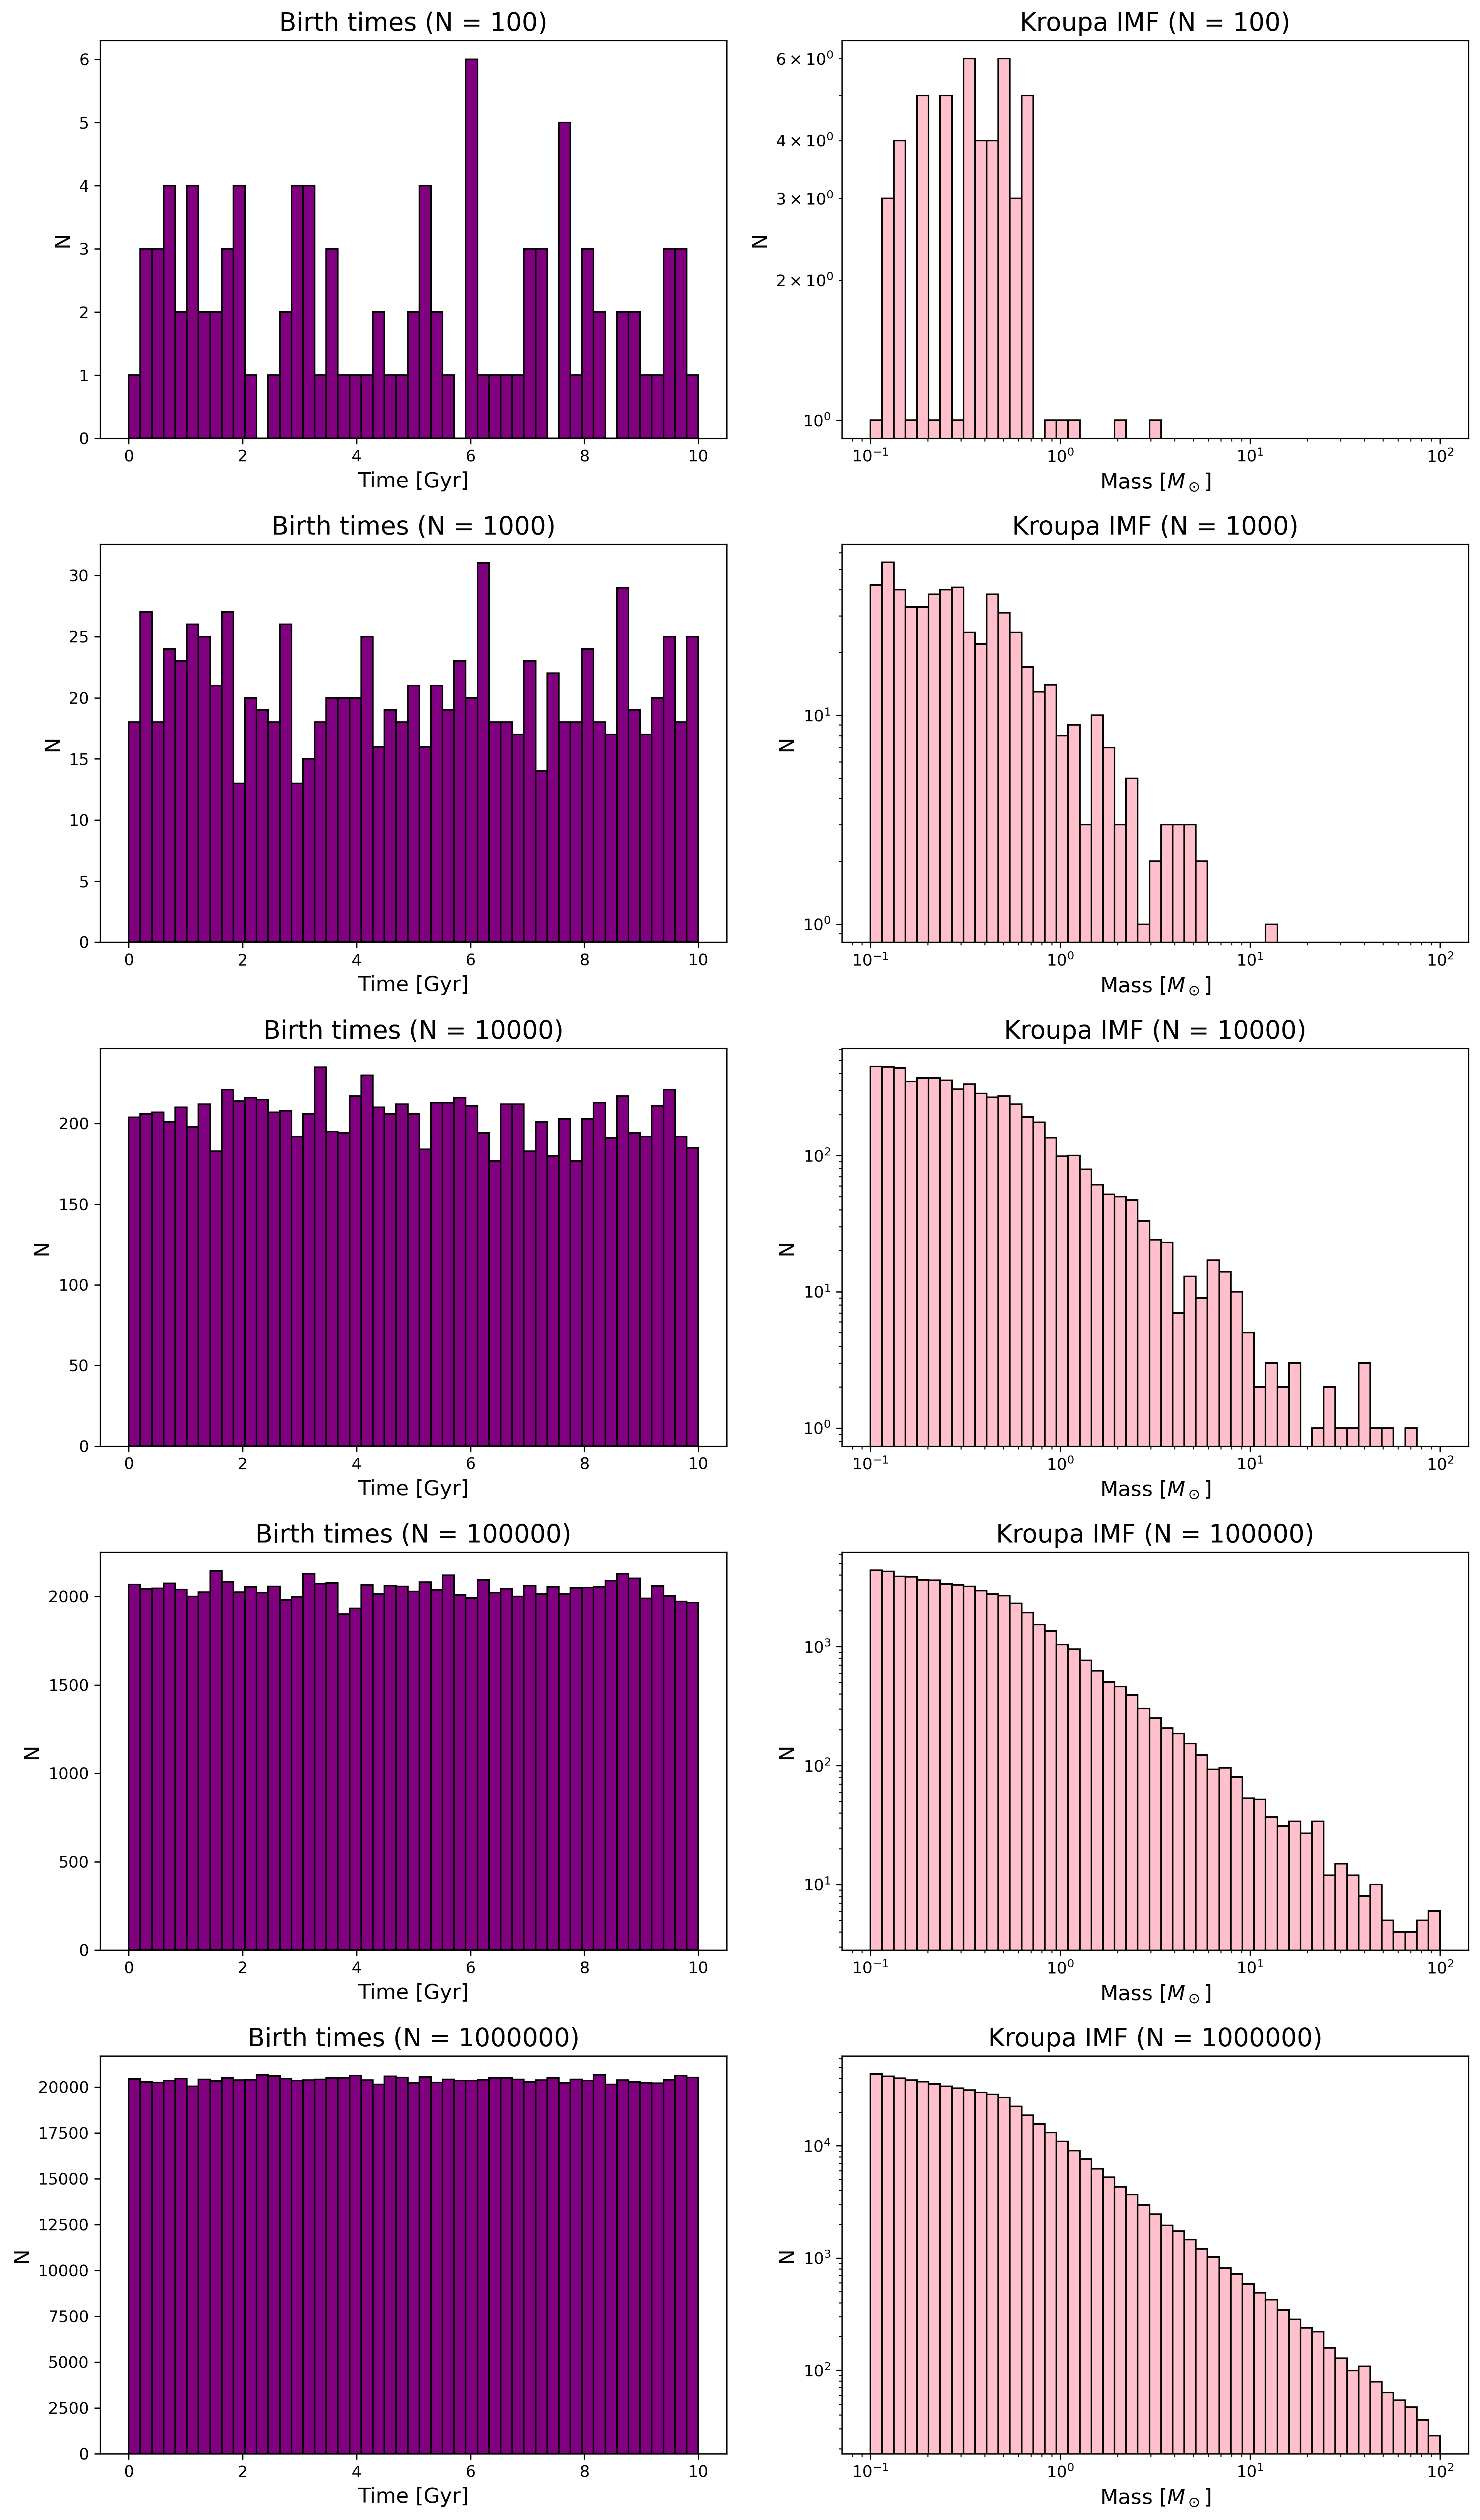

In [364]:
#Distribuciones para distinta cantidad de estrellas iniciales
np.random.seed(42)
N_values = [100, 1000, 10000, 100000, 1000000]
bins_t = np.linspace(0, 10, 50)
bins_m = np.logspace(np.log10(0.1), np.log10(100), 50)
fig, axes = plt.subplots(5, 2, figsize=(13, 22))
for i, N in enumerate(N_values):
    masas, tiempos = mckroupa(N)
    # Histograma de tiempos de nacimiento
    axes[i, 0].hist(tiempos, bins=bins_t,
        color="purple", edgecolor="black")
    axes[i, 0].set_title(f"Birth times (N = {N:})")
    axes[i, 0].set_xlabel("Time [Gyr]")
    axes[i, 0].set_ylabel("N")

    # Histograma de masas
    axes[i, 1].hist(
        masas, bins=bins_m,
        color="pink", edgecolor="black"
    )
    axes[i, 1].set_xscale("log")
    axes[i, 1].set_yscale("log")
    axes[i, 1].set_title(f"Kroupa IMF (N = {N:})")
    axes[i, 1].set_xlabel(r"Mass [$M_\odot$]")
    axes[i, 1].set_ylabel("N")

plt.tight_layout()
plt.savefig("CASOSESTRELLAS.png")
plt.show()


In [200]:
#Masas iniciales y masas finales para tipo de objeto

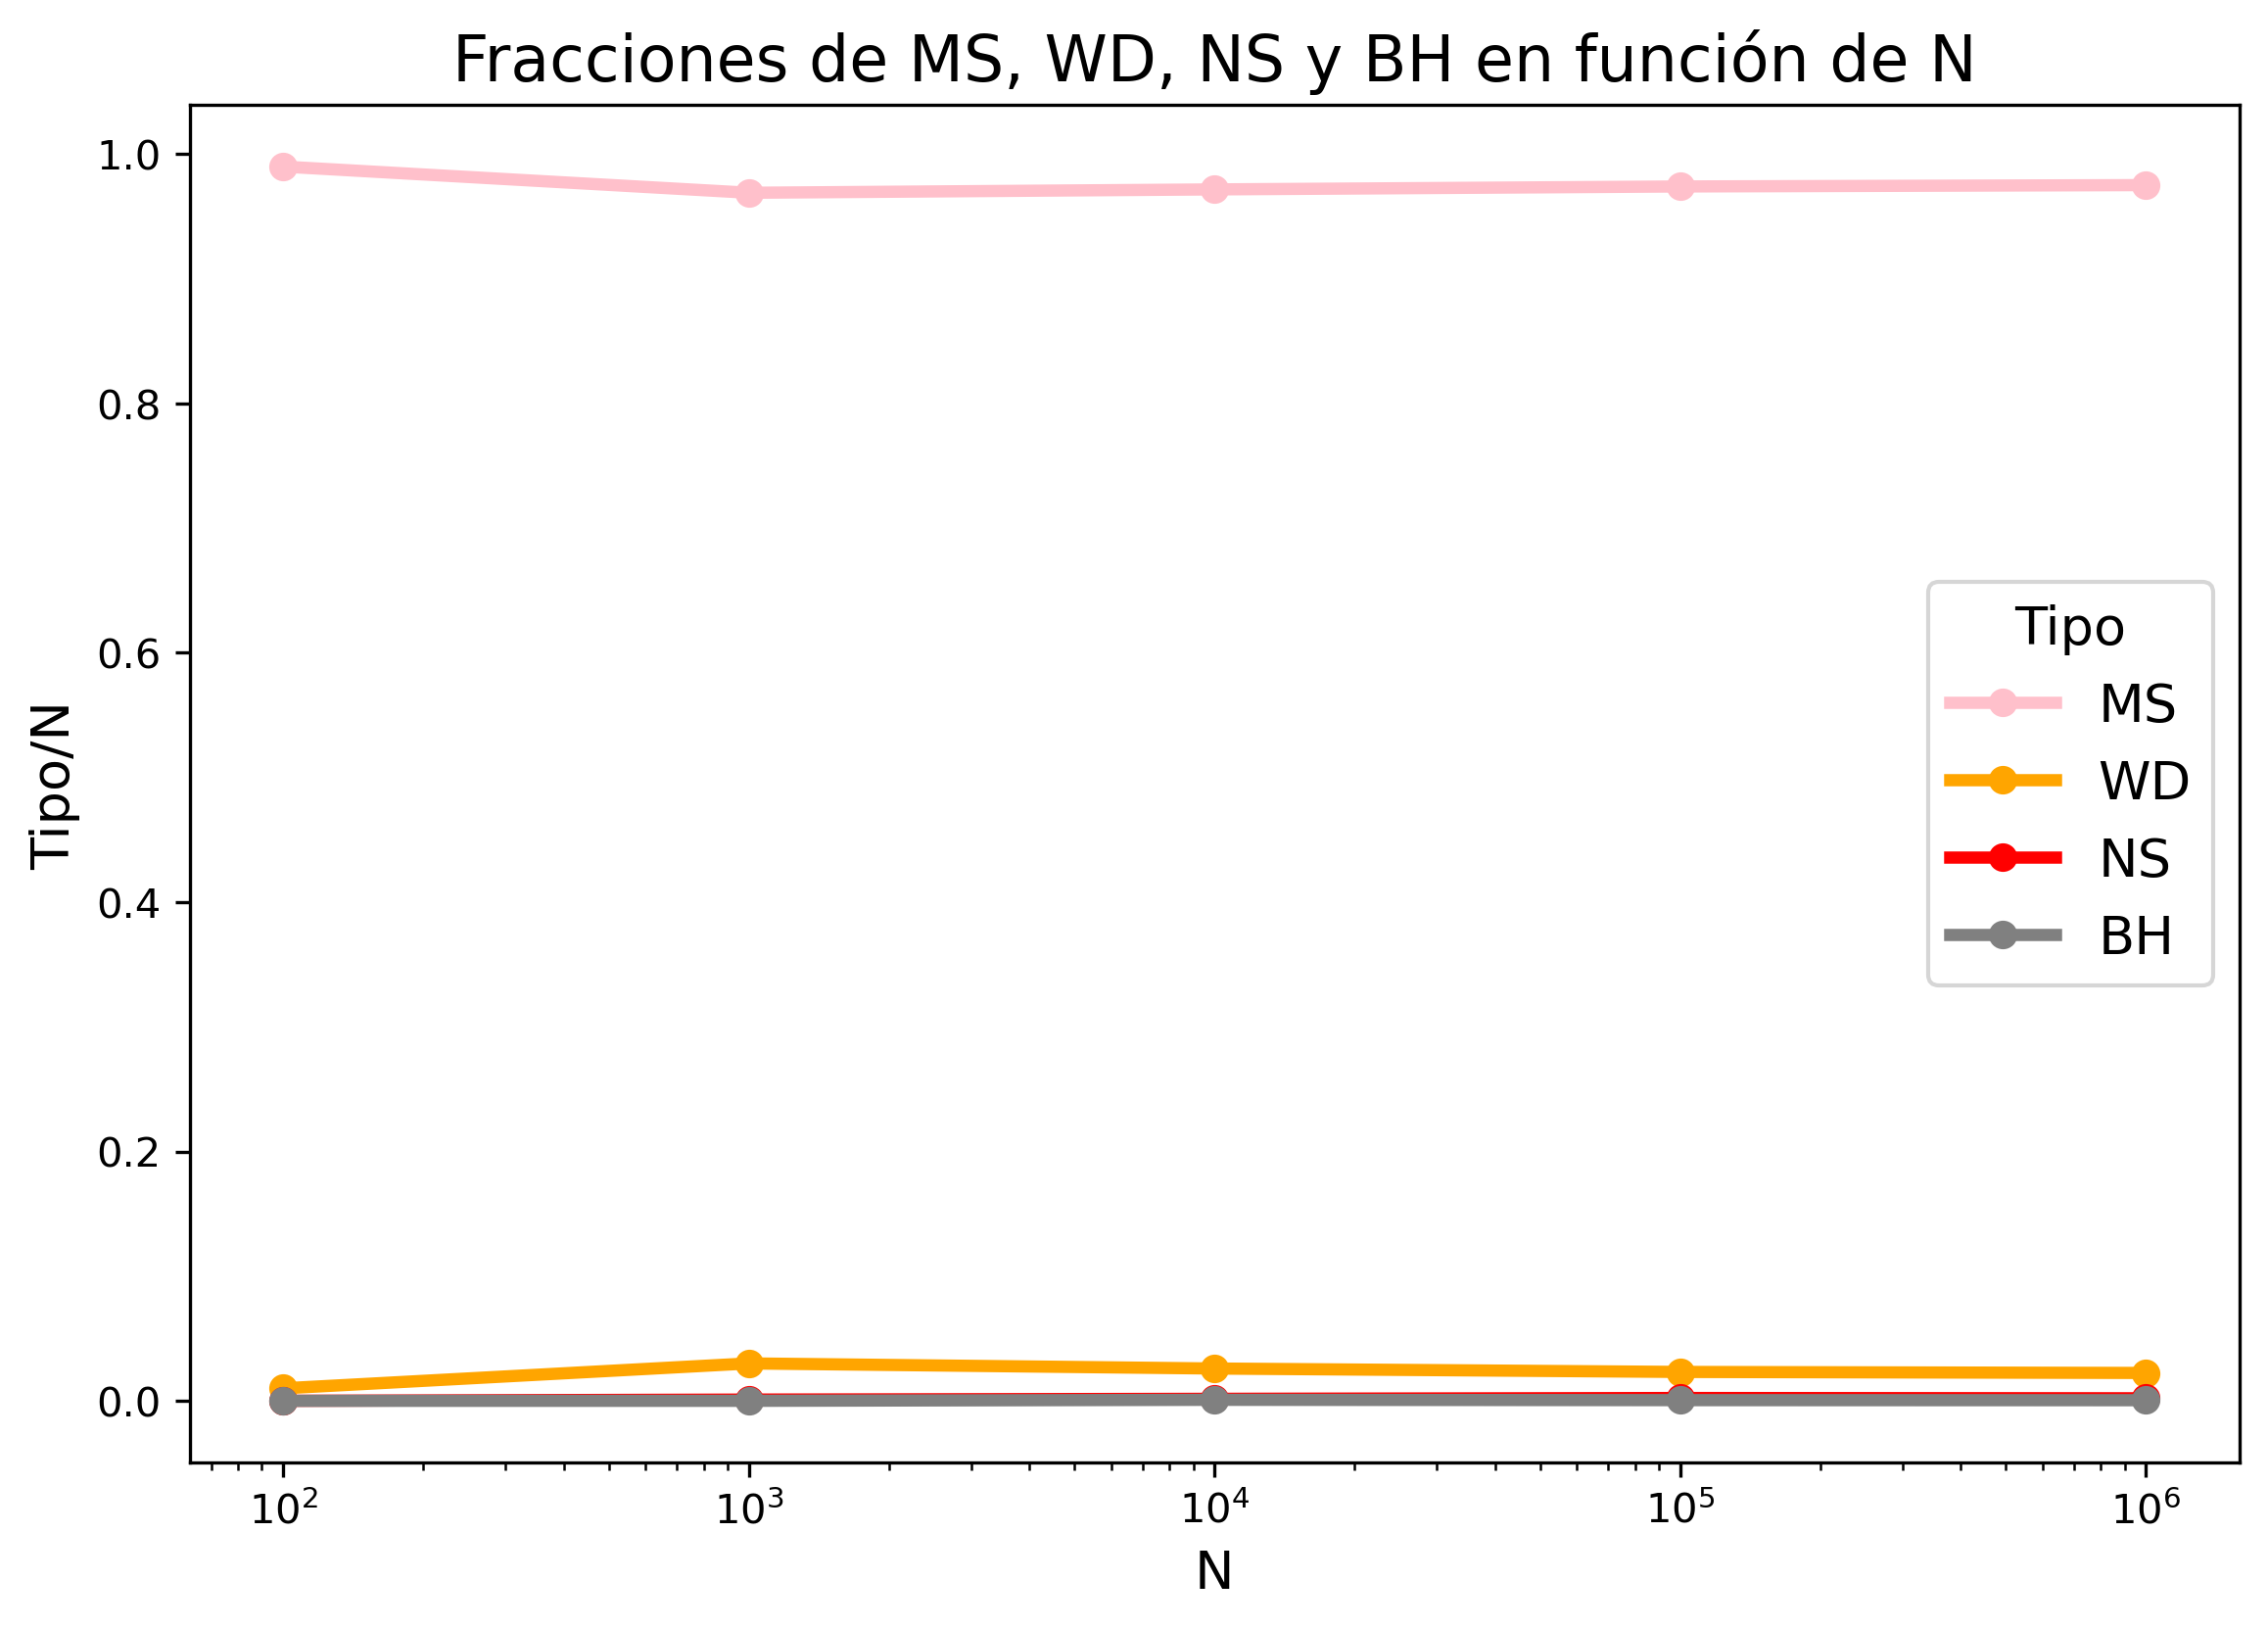

         N         MS         WD         NS         BH
       100     0.9900     0.0100     0.0000     0.0000
      1000     0.9690     0.0300     0.0010     0.0000
     10000     0.9717     0.0259     0.0016     0.0008
    100000     0.9740     0.0232     0.0023     0.0005
   1000000     0.9751     0.0223     0.0020     0.0005


In [67]:
#convergencia para distintas cantidades de estrellas iniciales
np.random.seed(42)
N_values = np.array([100, 1000, 10000, 100000, 1000000])
M_WD = 8.0
M_NS = 25.0

fracciones = {
    "MS": [],
    "WD": [],
    "NS": [],
    "BH": []
}
for N in N_values:
    masas, tiempos_nacimiento = mckroupa(N) #tomando en cuenta función definida
    edades = 10.0 - tiempos_nacimiento #edad de cada estrella
    t_MS = 10.0 * masas**(-2.5) #siguiendo tiempo de main sequence
    evolucionada = edades >= t_MS
    MS = ~evolucionada
    WD = evolucionada & (masas < M_WD) & (masas >= 0.8)
    NS = evolucionada & (masas >= M_WD) & (masas < M_NS)
    BH = evolucionada & (masas >= M_NS)
    fracciones["MS"].append(np.sum(MS) / N) #main sequence
    fracciones["WD"].append(np.sum(WD) / N) #enana blanca
    fracciones["NS"].append(np.sum(NS) / N) #estrella neutrones
    fracciones["BH"].append(np.sum(BH) / N) #black hole

plt.figure(figsize=(9, 6))
colores = {"MS": "pink","WD": "orange","NS": "red","BH": "gray"}

for tipo in fracciones:
    plt.plot(
        N_values,
        fracciones[tipo],
        marker="o",
        linewidth=3,
        label=tipo,
        color=colores[tipo]
    )

plt.xscale("log")
plt.xlabel("N")
plt.ylabel("Tipo/N")
plt.title("Fracciones de MS, WD, NS y BH en función de N")
plt.legend(title="Tipo")
plt.show()

print(f"{'N':>10} {'MS':>10} {'WD':>10} {'NS':>10} {'BH':>10}")
for i, N in enumerate(N_values):
    print(
        f"{N:10d} "
        f"{fracciones['MS'][i]:10.4f} "
        f"{fracciones['WD'][i]:10.4f} "
        f"{fracciones['NS'][i]:10.4f} "
        f"{fracciones['BH'][i]:10.4f}"
    )

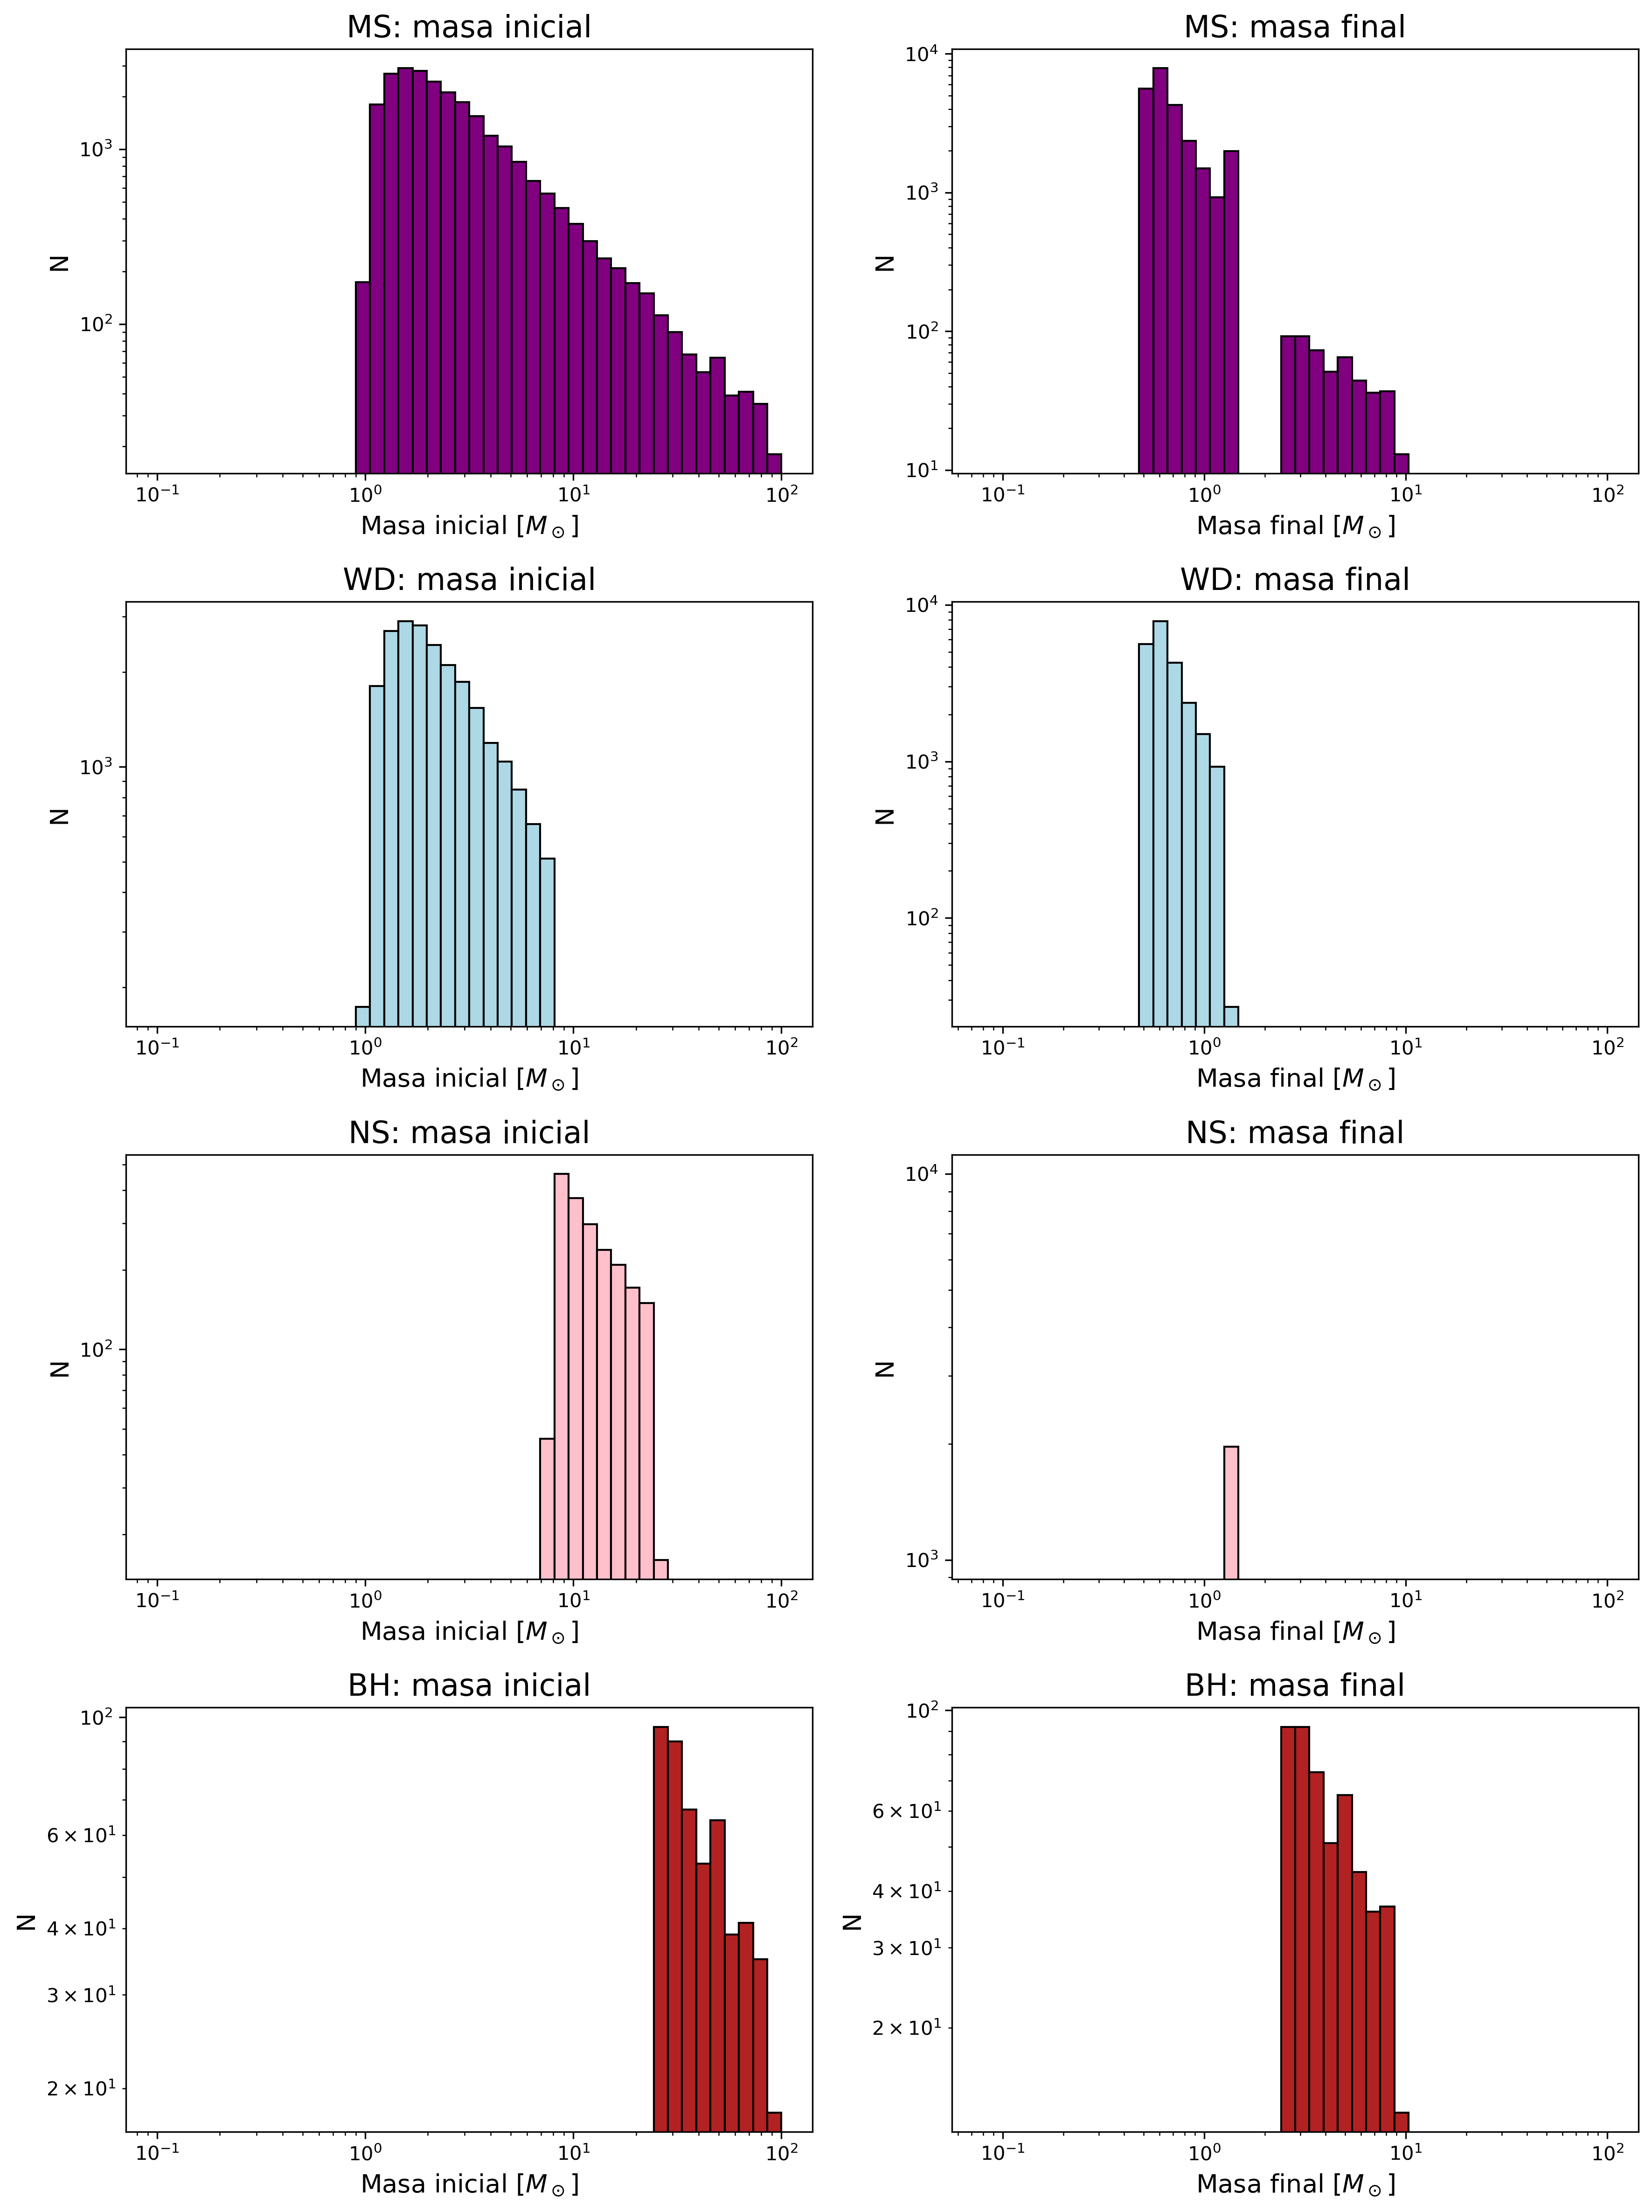

Tipo        Cantidad    Fracción    Masa inicial media    Masa final media
MS             25039      0.0250                 4.275               0.811
WD             22574      0.0226                 2.609               0.678
NS              1962      0.0020                13.051               1.400
BH               503      0.0005                44.816               4.482


In [81]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)
N = 1000000
masas_ini, tiempos_nacimiento = mckroupa(N)

# Edad actual de cada estrella [Gyr]
edades = 10.0 - tiempos_nacimiento

# Tiempo aproximado de vida en secuencia principal [Gyr]
t_MS = 10.0 * masas_ini**(-2.5)
evolucionada = edades >= t_MS

# Clasificación de los objetos
MS = evolucionada
WD = evolucionada & (masas_ini >= 0.8) & (masas_ini < 8)
NS = evolucionada & (masas_ini >= 8) & (masas_ini < 25)
BH = evolucionada & (masas_ini >= 25)

tipos = {
    "MS": MS,
    "WD": WD,
    "NS": NS,
    "BH": BH
}
# Masas finales: prescripciones simplificadas
masas_fin = np.full(N, np.nan)
masas_fin[MS] = masas_ini[MS]
masas_fin[WD] = 0.109 * masas_ini[WD] + 0.394
masas_fin[NS] = 1.4
masas_fin[BH] = 0.1 * masas_ini[BH]

bins = np.logspace(np.log10(0.1), np.log10(100), 45)
fig, axes = plt.subplots(4, 2, figsize=(12, 16))
colores = {
    "MS": "purple",
    "WD": "lightblue",
    "NS": "pink",
    "BH": "firebrick"
}
for i, (tipo, mask) in enumerate(tipos.items()):
    # Masas iniciales por tipo
    axes[i, 0].hist(
        masas_ini[mask],
        bins=bins,
        color=colores[tipo],
        edgecolor="black"
    )
    axes[i, 0].set_xscale("log")
    axes[i, 0].set_yscale("log")
    axes[i, 0].set_title(f"{tipo}: masa inicial")
    axes[i, 0].set_xlabel(r"Masa inicial [$M_\odot$]")
    axes[i, 0].set_ylabel("N")
    # Masas finales por tipo
    bins_finales = np.logspace(
        np.log10(0.08), np.log10(100), 45
    )
    axes[i, 1].hist(
        masas_fin[mask],
        bins=bins_finales,
        color=colores[tipo],
        edgecolor="black"
    )
    axes[i, 1].set_xscale("log")
    axes[i, 1].set_yscale("log")
    axes[i, 1].set_title(f"{tipo}: masa final")
    axes[i, 1].set_xlabel(r"Masa final [$M_\odot$]")
    axes[i, 1].set_ylabel("N")
plt.tight_layout()
plt.savefig("Otroscasosestrellas.png")
plt.show()
# Resumen numérico
print(f"{'Tipo':<8}{'Cantidad':>12}{'Fracción':>12}"
      f"{'Masa inicial media':>22}{'Masa final media':>20}")

for tipo, mask in tipos.items():
    n_tipo = np.sum(mask)

    if n_tipo > 0:
        print(
            f"{tipo:<8}{n_tipo:12d}"
            f"{n_tipo/N:12.4f}"
            f"{np.mean(masas_ini[mask]):22.3f}"
            f"{np.mean(masas_fin[mask]):20.3f}"
        )


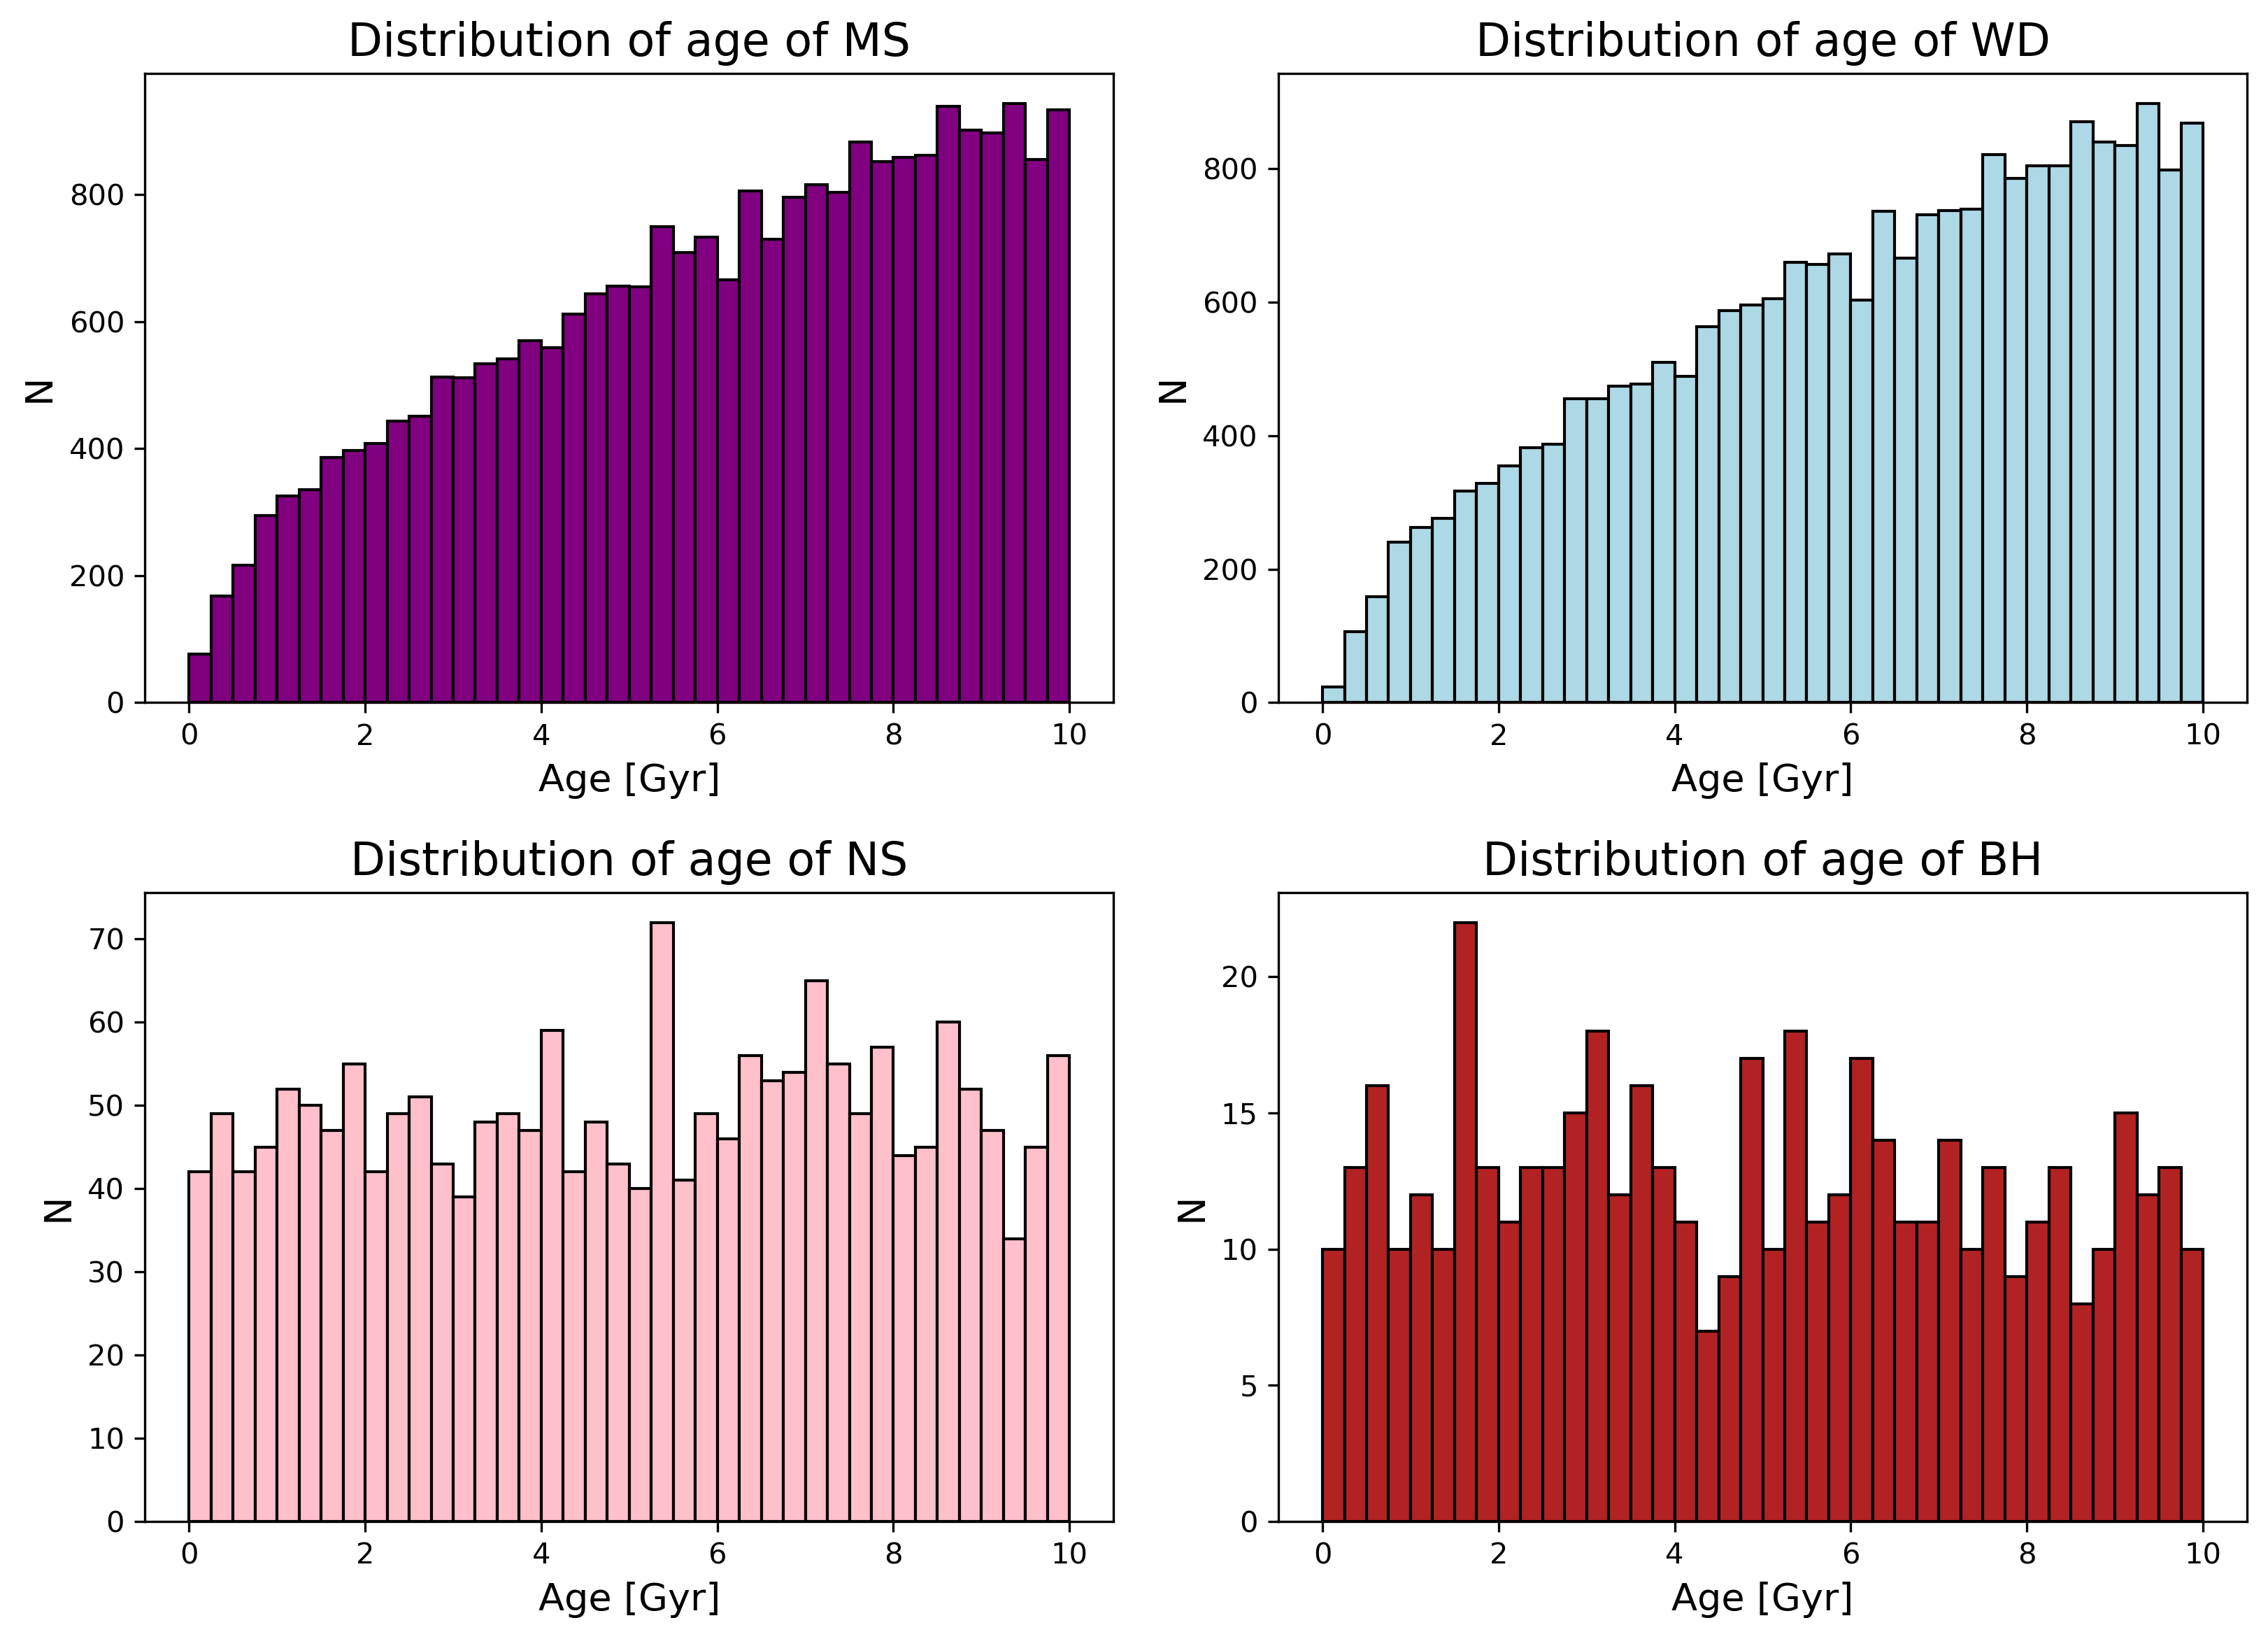

Type               N      Mean age      Median
MS             25039         6.039       6.364
WD             22574         6.148       6.469
NS              1962         5.084       5.248
BH               503         4.864       4.864


In [82]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)
N = 1_000_000
edad_galaxia = 10.0 #Gyr
masas_ini, tiempos_nacimiento = mckroupa(N, edad_galaxia=edad_galaxia) #utilizando la distribución de Kroupa
edades = edad_galaxia - tiempos_nacimiento #edades actuales
t_MS = 10.0 * masas_ini**(-2.5) #ms time
evolucionada = edades >= t_MS #remnant
MS = evolucionada
WD = (evolucionada & (masas_ini >= 0.8) & (masas_ini < 8))
NS = (evolucionada & (masas_ini >= 8) & (masas_ini < 25))
BH = evolucionada & (masas_ini >= 25)

tipos = {"MS": MS,"WD": WD,"NS": NS,"BH": BH}
colores = {
    "MS": "purple",
    "WD": "lightblue",
    "NS": "pink",
    "BH": "firebrick"
}

fig, axes = plt.subplots(2, 2, figsize=(11, 8)) #esto para ponerlo todo junto mejor
bins = np.linspace(0, edad_galaxia, 41)
for ax, (tipo, mask) in zip(axes.flat, tipos.items()):

    ax.hist(
        edades[mask],
        bins=bins,
        color=colores[tipo],
        edgecolor="black"
    )

    ax.set_title(f"Distribution of age of {tipo}")
    ax.set_xlabel("Age [Gyr]")
    ax.set_ylabel("N")

plt.tight_layout()
plt.savefig("Ages.png")
plt.show()

# Resumen estadístico
print(
    f"{'Type':<8}{'N':>12}"
    f"{'Mean age':>14}{'Median':>12}"
)

for tipo, mask in tipos.items():
    edades_tipo = edades[mask]

    if len(edades_tipo) > 0:
        print(
            f"{tipo:<8}{len(edades_tipo):12d}"
            f"{np.mean(edades_tipo):14.3f}"
            f"{np.median(edades_tipo):12.3f}"
        )


/var/folders/36/rk32flss4bj4sbk5qc_2v8l00000gn/T/ipykernel_10735/3939315879.py:27: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig("agemetal.png")


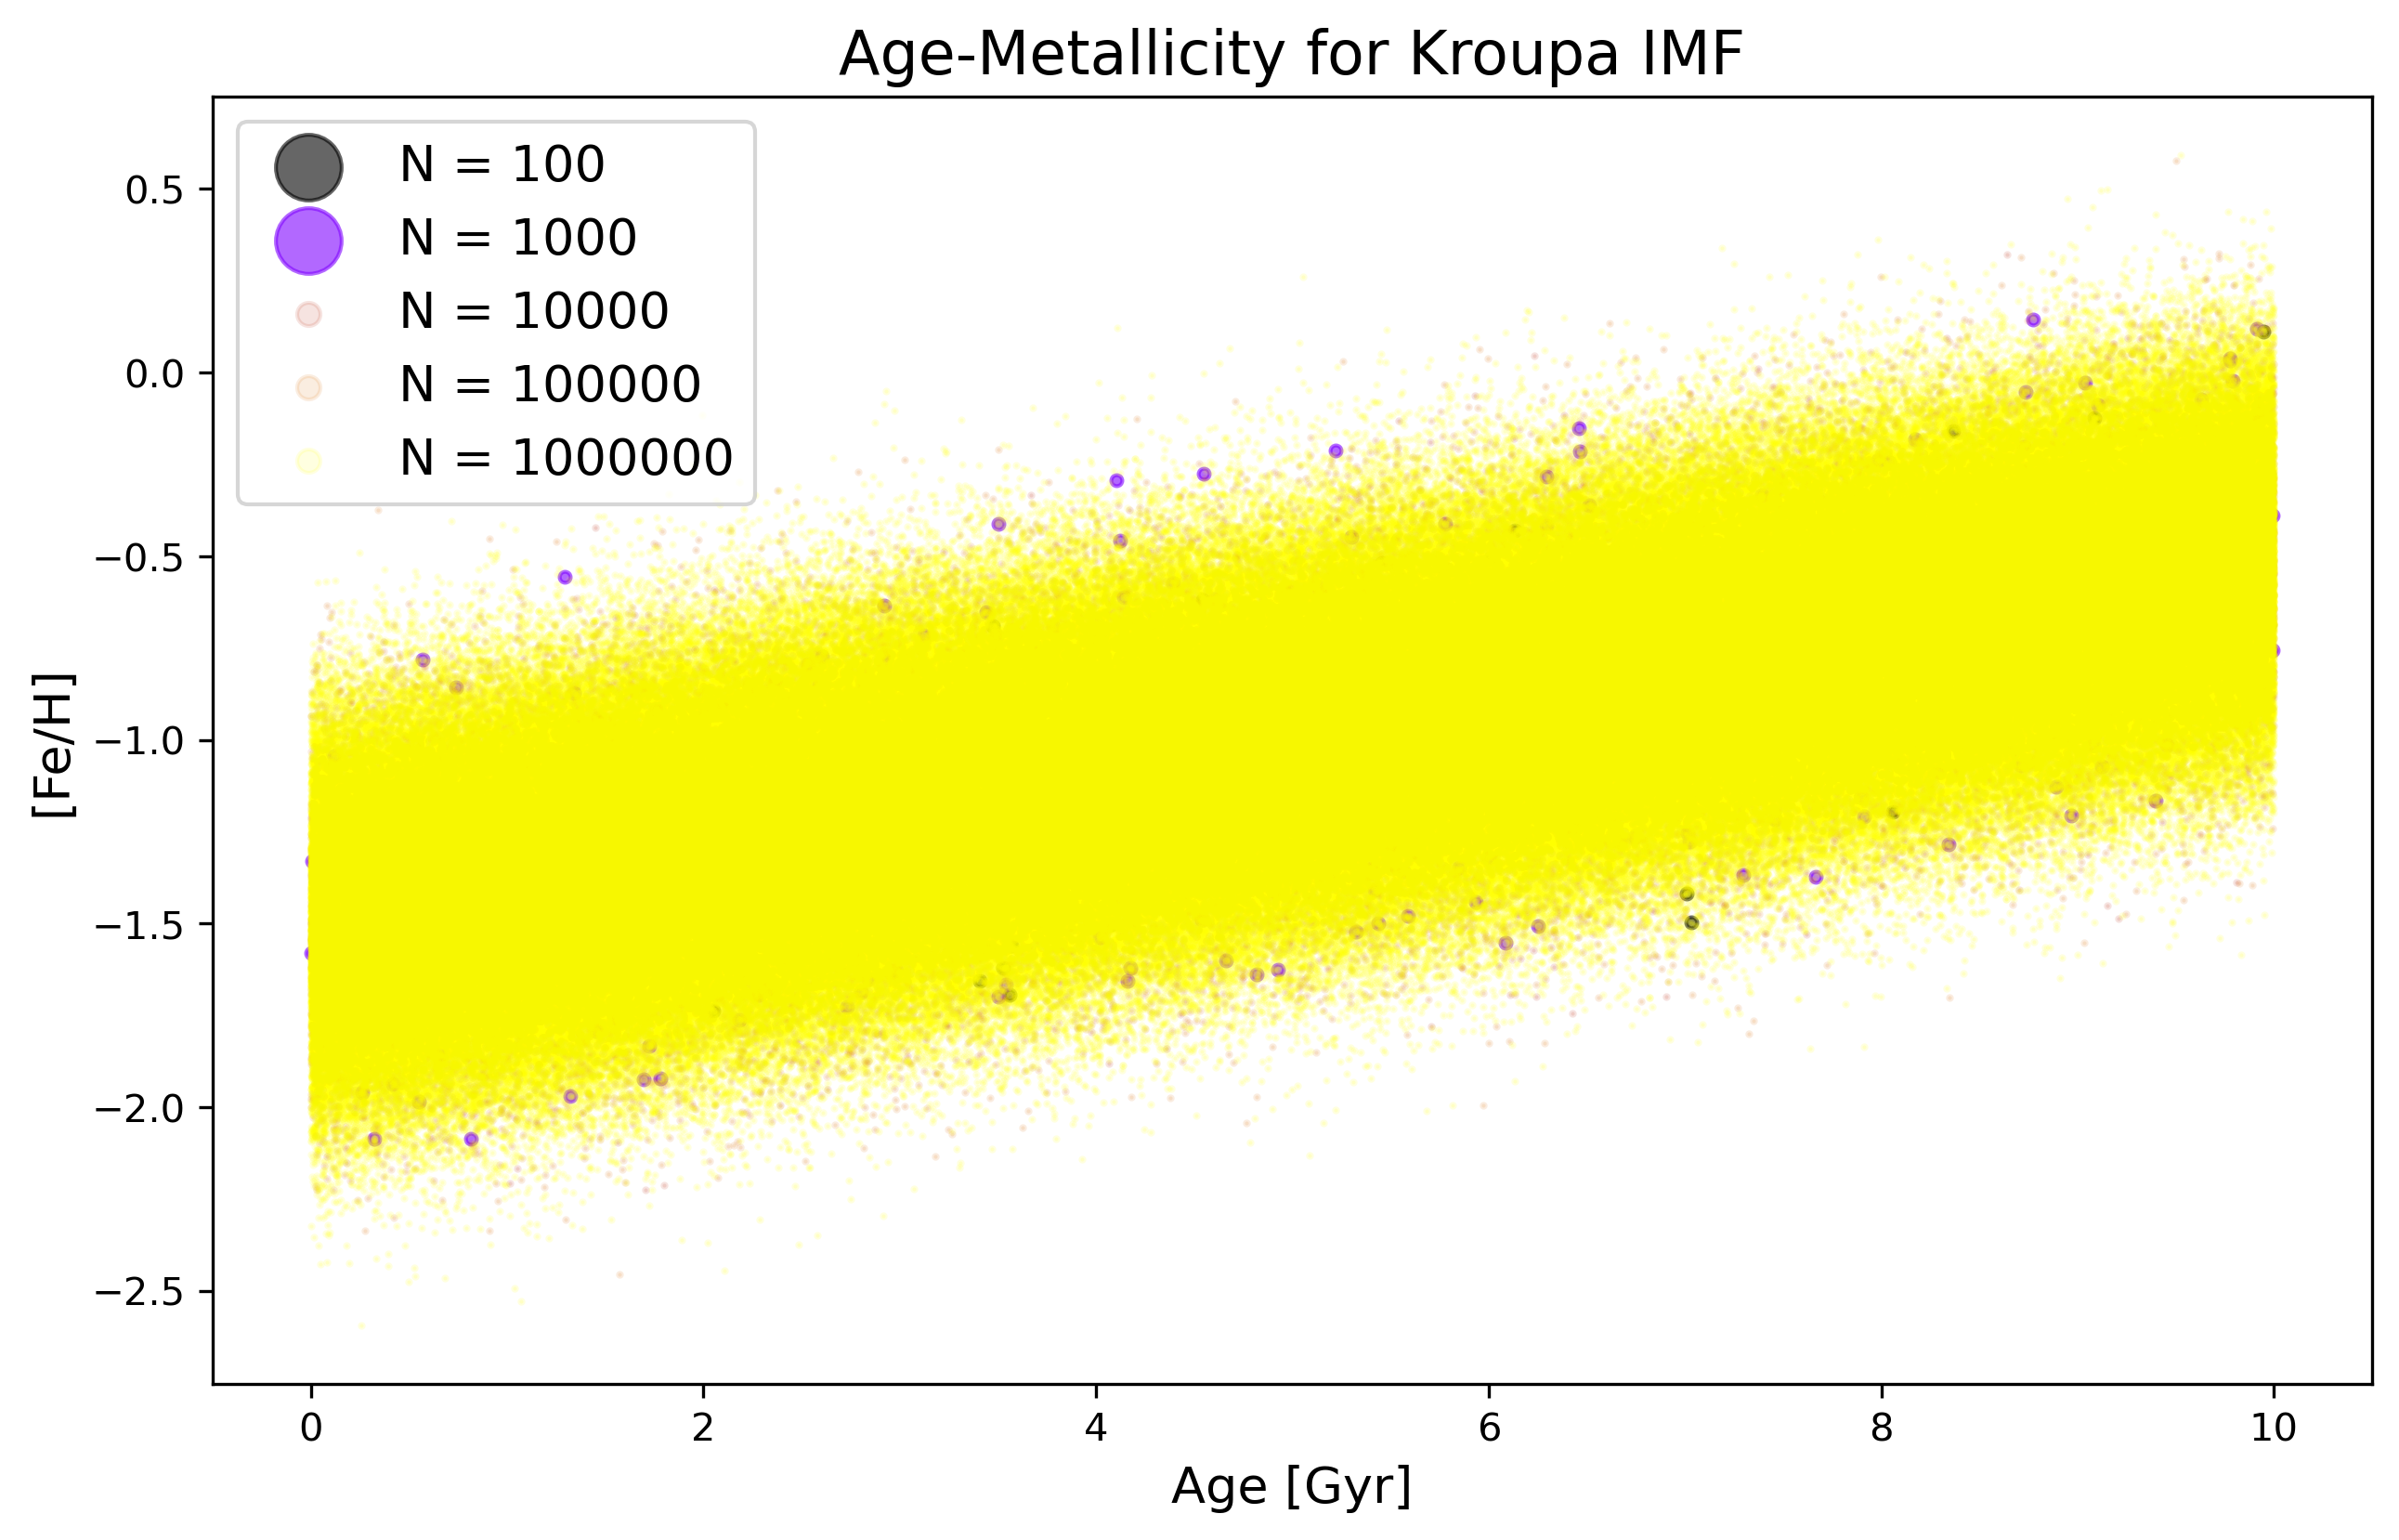

In [94]:
np.random.seed(42) #siempre se define la semilla para reproducibilidad kroupa 2001

masses = mckroupa(N, edad_galaxia=edad_galaxia)
N_values = [100, 1000, 10000, 100000, 1000000]
fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.cm.gnuplot(np.linspace(0, 1, len(N_values)))
for N, color in zip(N_values, colors):
    masa = mckroupa(N) #kroupa función definida antes
    edad = np.random.uniform(0, 10, N) #para distribución uniforme de edades
    # Metalicidad inicial ilustrativa
    metalicidad = -1.5 + 0.10 * edad
    metalicidad += np.random.normal(0, 0.25, N)
    # Reducir el tamaño de los puntos para N grandes
    ax.scatter(
        edad,
        metalicidad,
        s=8 if N <= 1000 else 1,
        alpha=0.6 if N <= 1000 else 0.12,
        color=color,
        rasterized=True,
        label=f"N = {N:}"
    )
ax.set_xlabel("Age [Gyr]", fontsize=13)
ax.set_ylabel("[Fe/H]", fontsize=13)
ax.set_title("Age-Metallicity for Kroupa IMF")
ax.legend(markerscale=6)
plt.savefig("agemetal.png")
plt.show()

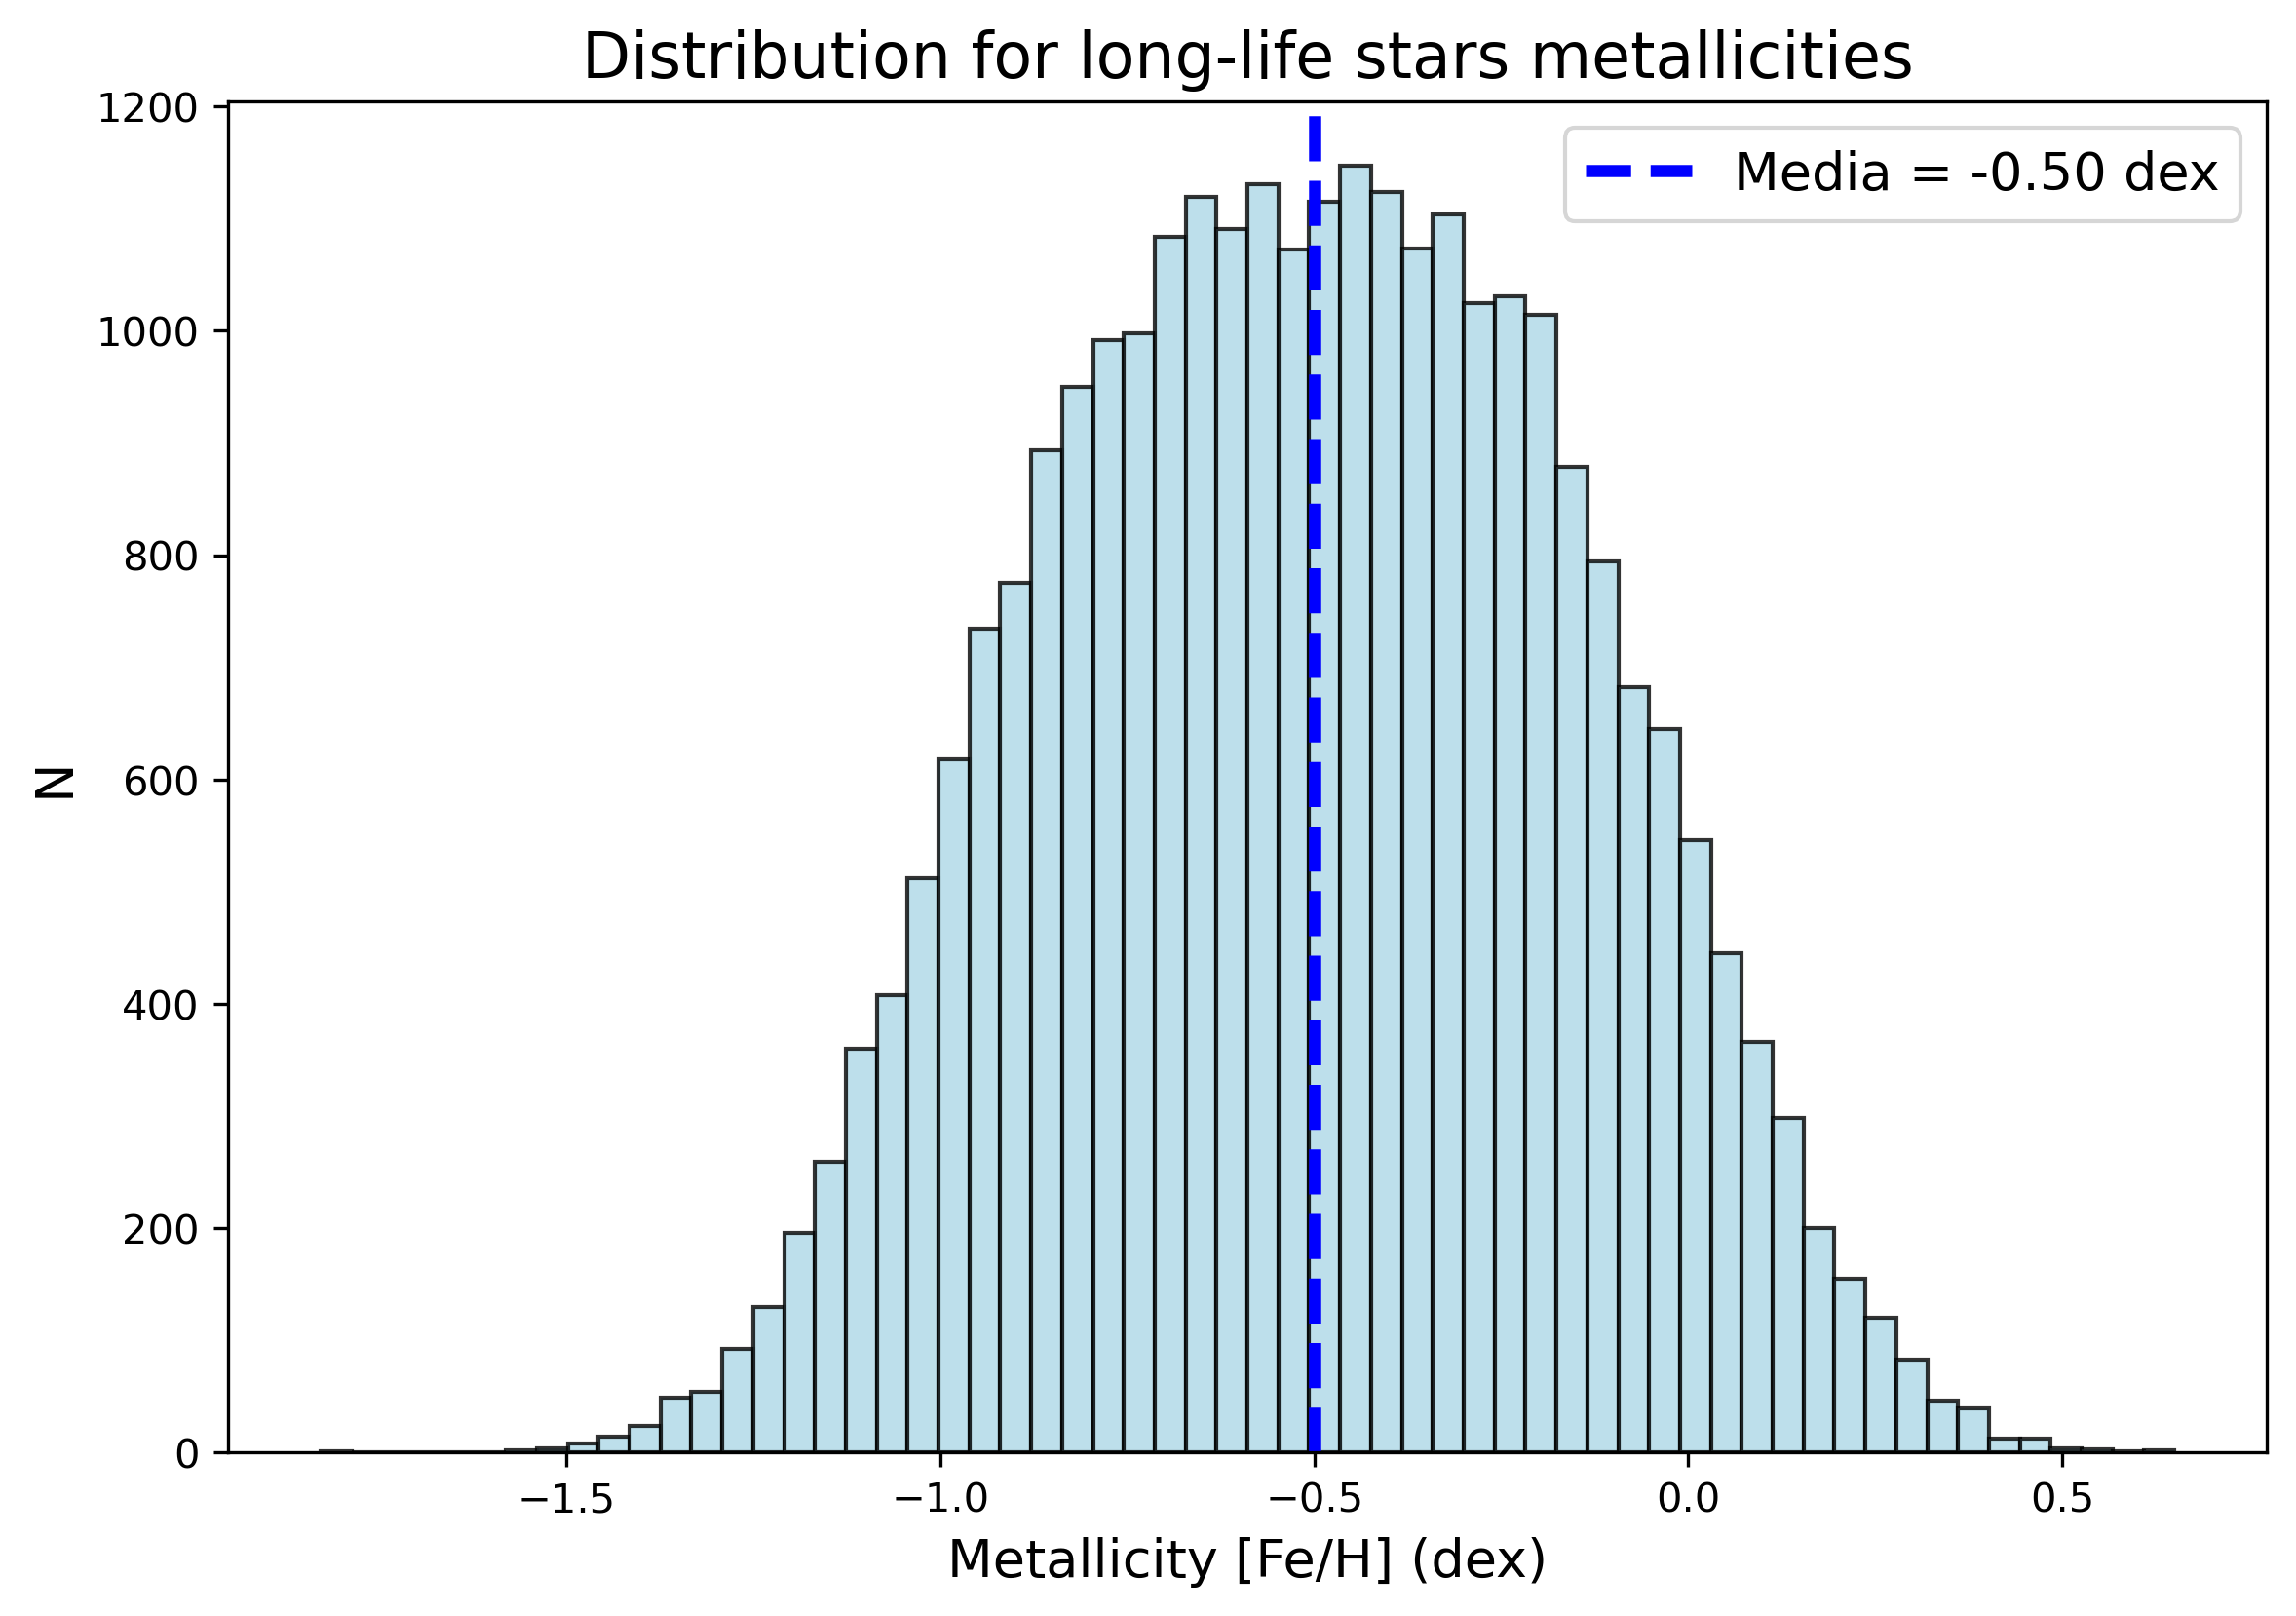

N long-lifetime: 27535
population fraction: 0.9178
mean [Fe/H]: -0.500 dex
std: 0.349 dex


In [316]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)
N = 30000
edad_galaxia = 10.0
# Simulación de masas y tiempos de nacimiento
masas, tiempos_nacimiento = mckroupa(N, edad_galaxia=edad_galaxia)
edades = edad_galaxia - tiempos_nacimiento #edad definida con tiempo galaxia - tiempos cuando nacen
# Seleccionar estrellas de larga vida
larga_vida = masas < 0.8
masas_lv = masas[larga_vida] #como antes, asociación
edades_lv = edades[larga_vida]
tiempos_lv = tiempos_nacimiento[larga_vida]

# Modelo ilustrativo de enriquecimiento químico
FeH_inicial = -1.0
FeH_final = 0.0
dispersion = 0.2

FeH_media = (
    FeH_inicial
    + (FeH_final - FeH_inicial)
    * tiempos_lv / edad_galaxia
)

FeH_lv = FeH_media + np.random.normal(
    0, dispersion, len(masas_lv)
)

# Histograma de metalicidades
plt.figure(figsize=(9, 6))

plt.hist(
    FeH_lv,
    bins=60,
    color="lightblue",
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    np.mean(FeH_lv),
    color="blue",
    linestyle="--",
    linewidth=3,
    label=f"Media = {np.mean(FeH_lv):.2f} dex"
)
plt.xlabel(r"Metallicity [Fe/H] (dex)")
plt.ylabel("N")
plt.title("Distribution for long-life stars metallicities")
plt.legend()
plt.show()
# Estadísticas
print("N long-lifetime:", len(masas_lv))
print(f"population fraction: {len(masas_lv)/N:.4f}")
print(f"mean [Fe/H]: {np.mean(FeH_lv):.3f} dex")
print(f"std: {np.std(FeH_lv):.3f} dex")

<h2 style="color:fuchsia; font-family:; text-align:center;font-size:17px">
  ❁۪ ｡˚ Desafío científico: Detectar el G-dwarf problem ❁۪ ｡˚
</h2>

Se proporcionará una distribución observacional de metalicidades para estrellas de larga vida del vecindario solar, basada en muestras publicadas en la literatura. El objetivo será contrastar una predicción concreta del closed-box model con observaciones.

Seleccione estrellas simuladas de baja masa que aún permanezcan en secuencia principal. Como proxy inicial de una población de G dwarfs se utilizará
0.8 < M_initial / M☉ < 1.05

Preguntas científicas que deben quedar respondidas

1.  ¿Cómo cambia la población simulada al aumentar N y cuándo se estabilizan las principales fracciones?
2.  ¿Qué ingredientes del modelo controlan principalmente la cantidad de MS, WD, NS y BH?
3.  ¿Qué relación edad–metalicidad produce el closed-box model y por qué?
4.  ¿La MDF del closed box es consistente con la muestra observacional?
5.  ¿Qué evidencia encuentran a favor o en contra del G-dwarf problem en su comparación?
6.  ¿Qué cambia físicamente al permitir infall de gas y cómo se refleja ese cambio en la MDF?
7.  ¿Cuáles son las limitaciones más importantes de tratar la Vía Láctea como una población one-zone?


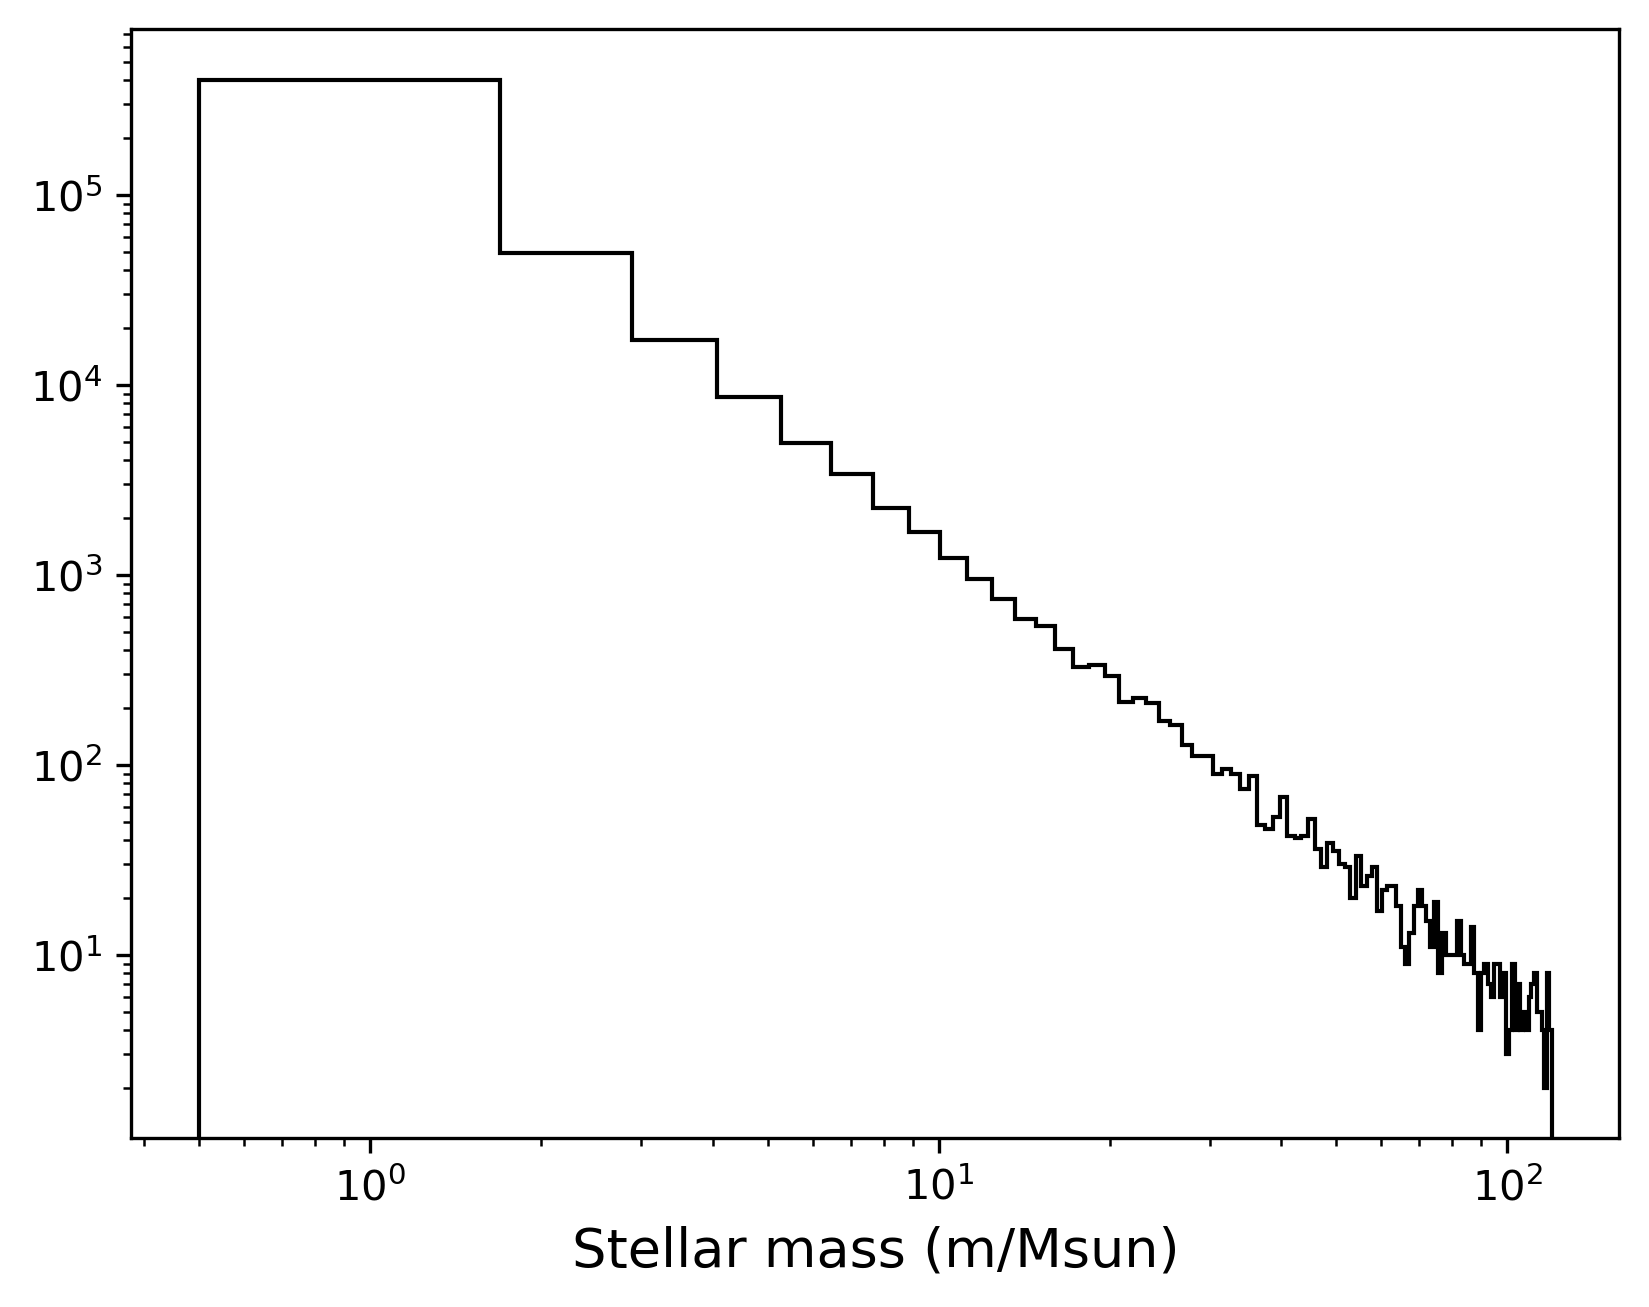

In [118]:

#para coding project mc
#IMF-> distribución teórica de masas 
#de una población estelar al nacer
#Salpeter -> primera IMF
#limites: 0.4 m/Msun < 10
#provenencia de distribucion de masa IMF power law, no es una distribucion uniforme (no se distribuyen masas uniformemente)
#m_teorico = np.linspace(0.0, 1.0, 500) #para que los valores sean de 0 a 1, porque en ejercicio anterior x=[1,10]
#p_teorica = (((0.4**(-1.35))-(m_teorico**(-1.35)))/((0.4**(-1.35))-mmax**(-1.35))) #C=39202.29, ya está constante normalizadora

def salpeter_imf(nstars,mmin,mmax,alpha):
    gamma=1-alpha 
    u = np.random.uniform(0.0,1.0,size=nstars) #distribucion uniforme entre 0 y 1
    term = (1.0-u)*(mmin**gamma)+u*(mmax**gamma) #inversa
    masses = term**(1.0/gamma)
    return masses
nstars=500000
mmin=0.5
mmax=120.0
alpha=2.35
masses = salpeter_imf(nstars,mmin=mmin,mmax=mmax, alpha=alpha)

plt.hist(masses, bins=100, histtype='step', color='black') #Visualización de la distribución
#plt.plot(m_teorico, p_teorica, linewidth=2, label="Distribución teórica")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Stellar mass (m/Msun)")
plt.show()

#limitación masa minima

closed box model for chemical evolution

-Simple models of galactic chemical evolution are given at time and specific region in galaxy.
-How do we study the chemical evolution? Gas accretion and fraction of gas in region turning into stars (SF efficiency). And metals returned to the ISM from gen of stars and see how much gas is lost.


Instantaneous recycling approximation